# Lecture-Theatre Evacuation: The Faster-Is-Slower Effect and a Door Obstacle

### Summary
This notebook simulates the evacuation of a 150-seat tiered lecture theatre (10 rows, two aisles, one 1.2 m exit) with a social-force model (Helbing et al., 2000): driving force, exponential social repulsion, elastic body compression and sliding friction, integrated with velocity Verlet and accelerated with Numba.

**Question:** does a higher desired speed slow the evacuation (faster-is-slower), and does a circular pillar in front of the exit improve the outflow?

**Method and checks:** every number is a Monte Carlo mean over seeds with a 95% Student-t confidence interval; pillar and no-pillar runs are paired by seed (common random numbers). The code is verified by analytic checks (single-agent relaxation with measured order of accuracy, wall and pillar stand-off distances), a limiting case (a pillar outside the room changes nothing), conservation of people, agreement of the cell-list and brute-force force routines, serial-vs-parallel agreement, a coverage test of the confidence-interval code and two time-step studies.

**Main findings (full run):** the evacuation time is shortest at about 3 m/s and rises again from about 5 m/s; the effect needs sliding friction and is strongest at narrow doors; a centred pillar did not help up to 5 m/s (see Section 6).

**Run modes.** `FULL_RUN = False` (default) is the quick mode for *Runtime -> Run all* (about 9 minutes on free Colab, including the three extension checks 5.12 to 5.14, which always run). `FULL_RUN = True` is the long study (about 60 minutes) behind the numbers quoted in Section 6. Section 6 states which run each number comes from.


In [84]:
# Setup Cell - Installs, Imports, and Parameter Definition

!pip install -q numba

import sys
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import numba
from numba import njit

BASE_SEED = 42

# ---- run-time settings: with FULL_RUN = False the whole notebook, including the extension checks 5.12 to 5.14, is sized to finish in about 9 minutes on free Colab ----
# (estimate from the cell timings of an earlier run; read 'Total run time' in the last cell to check it on your runtime)
FULL_RUN = False     # True: the longer study (more seeds, speeds and extra studies, about 60 minutes)
RUN_MODE = 'full' if FULL_RUN else 'quick'   # used in the names of the result CSV files
N_SEEDS = 10 if FULL_RUN else 4        # replications per point in the main experiment
N_SMALL = 6 if FULL_RUN else 3         # replications per point in the secondary studies
SPEEDS_MAIN = [1.5, 2.0, 3.0, 4.0, 5.0, 7.0] if FULL_RUN else [1.5, 3.0, 7.0]
# Quick-mode sizes are fixed (no run-time guard), so every check below always runs and nothing is skipped on a slow machine.
# If a run takes clearly longer than 10 minutes, shorten the quick mode with SPEEDS_MAIN = [3.0, 7.0] (saves about 50 s).
T_START = time.time()

print(f"Python Version: {sys.version}")
print(f"NumPy Version: {np.__version__}")
print(f"Matplotlib Version: {matplotlib.__version__}")
print(f"Numba Version: {numba.__version__}")

PARAMS = {
    'm': 80.0,              # Pedestrian mass [kg]
    'r_min': 0.25,          # Minimum body radius [m]
    'r_max': 0.35,          # Maximum body radius [m] (uniform random body radius)
    'tau': 0.5,             # Relaxation time [s]
    'A': 2000.0,            # Social interaction force strength [N]
    'B': 0.08,              # Social interaction force range [m]
    'k': 1.2e5,             # Body compression force constant [N/m]
    'kappa': 2.4e5,         # Sliding friction force constant [kg/(m*s)]
    'dt_trial': 0.01,       # Trial time step [s], final value chosen from convergence study
    'v0': 1.5,              # Desired speed [m/s]

    # Real Geometry Parameters
    'seat_pitch': 0.75,     # Spacing between seat centres along a row [m]
    'seats_per_row': 15,    # Number of seats per row
    'rows': 10,             # Number of seating rows
    'row_depth': 0.9,       # Back-to-front depth of a row space [m]
    'aisle_width': 1.2,     # Main corridor width [m]
    'front_depth': 3.0,     # Depth of front area near exit [m]
    'exit_width': 1.2,      # Width of the exit door [m]
    'obstacle_radius': 0.3, # Obstacle radius [m]
    'obstacle_dist': 1.5,   # Obstacle distance from exit [m]
    'n_aisles': 2,          # Number of aisles inside room
    'block_seats': 5        # Number of seats per row block
}

# Enforce consistency check
assert PARAMS['seats_per_row'] == (PARAMS['n_aisles'] + 1) * PARAMS['block_seats'], "Geometry block parameters inconsistent!"
print("Setup parameters compiled and validated.")

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy Version: 2.4.6
Matplotlib Version: 3.10.0
Numba Version: 0.64.0
Setup parameters compiled and validated.


## 1. Problem and question

### Real-World Situation
During an emergency evacuation in a structured, tiered lecture theatre, occupants must navigate through highly constrained architectural corridors (such as aisles and rows of fixed seating) to reach a single narrow exit. As urgency levels rise, panic can lead to dense crowding, physical crushing, and friction-driven structural blockages near the exit.

### Central Scientific Question
*Does a higher desired speed slow down the overall evacuation time, and can placing a rigid structural obstacle immediately upstream of the exit gate improve outflow?*

### Practical Importance
Answering this allows architects and safety designers to construct non-intuitive safety interventions (like pillars or structural dividers) that may reduce crushing risk.

### Scope and Assumptions
- Pedestrians are simulated as two-dimensional physical disks moving in a bounded geometry.
- Group behaviors, leadership, panic-induced injuries, and impatience are excluded.
- The lecture theatre is physically tiered, but our model is a 2D plan-view representation and ignores the slope.
- Occupants possess complete knowledge of the room layout and navigate toward designated exit waypoints.

## 2. Model, assumptions and equations

### Key Model Assumptions
1. Pedestrians move within a 2D plane ($x, y$) without vertical variance, ignoring physical steps or slopes.
2. Every pedestrian has a constant mass but body radius is assigned as a uniform random variable in [0.25, 0.35] m representing soft-contact discs.
3. Each agent maintains a constant target desired speed $v_0$ throughout the simulation run.
4. Seat backs are modelled as walls, so each row is a narrow lane and people leave it sideways toward an aisle.

### Governing Mathematical Equations

The acceleration of agent $i$ is determined by Newton's Second Law:
$$m_i \frac{d\mathbf{v}_i}{dt} = \mathbf{f}_i^{\text{des}} + \sum_{j \neq i} \mathbf{f}_{ij} + \sum_{w} \mathbf{f}_{iw}$$

#### 1. Desired Force
$$\mathbf{f}_i^{\text{des}} = m_i \frac{v_0 \mathbf{e}_i(t) - \mathbf{v}_i(t)}{\tau}$$
Where $\mathbf{e}_i(t)$ is the unit vector pointing toward the agent's target waypoint, and $\tau$ is the velocity relaxation time.

#### 2. Pair Interaction Force (Social + Physical Contact)
$$\mathbf{f}_{ij} = \left[ A \exp\left( \frac{r_{ij} - d_{ij}}{B} \right) + k g(r_{ij} - d_{ij}) \right] \mathbf{n}_{ij} + \kappa g(r_{ij} - d_{ij}) (\Delta v_{ji} \cdot \mathbf{t}_{ij}) \mathbf{t}_{ij}$$
Where:
- $r_{ij} = r_i + r_j$ is the sum of radii, and $d_{ij} = \|\mathbf{x}_i - \mathbf{x}_j\|$ is the center-to-center distance.
- $\mathbf{n}_{ij} = (\mathbf{x}_i - \mathbf{x}_j)/d_{ij}$ is the normal direction pointing from $j$ to $i$.
- $\mathbf{t}_{ij} = (-n_{ij,y}, n_{ij,x})$ is the tangent direction.
- $g(x) = \max(0, x)$ is a ramp function activated only upon physical compression overlap.
- $\Delta v_{ji} = (\mathbf{v}_j - \mathbf{v}_i)$ represents relative sliding velocity.

#### 3. Wall Interaction Force
$$\mathbf{f}_{iw} = \left[ A \exp\left( \frac{r_i - d_{iw}}{B} \right) + k g(r_i - d_{iw}) \right] \mathbf{n}_{iw} - \kappa g(r_i - d_{iw}) (\mathbf{v}_i \cdot \mathbf{t}_{iw}) \mathbf{t}_{iw}$$
Where:
- $d_{iw}$ is the distance from the center of person $i$ to the nearest point on the wall segment.
- $\mathbf{n}_{iw}$ is the unit vector pointing from that nearest point toward the person.
- $\mathbf{t}_{iw} = (-n_{iw,y}, n_{iw,x})$ is the unit tangent direction.
- Circular obstacles (pillars) are handled with an identical physical structure, where $d_{iw}$ is calculated as the radial distance from the agent center to the boundary of the physical pillar circle.

### Parameter Summary Table
| Symbol | Parameter Description | Standard Value | Unit | Source / Assumption |
|:---:|:---|:---:|:---:|:---|
| $m$ | Pedestrian mass | 80 | kg | Helbing et al. (2000) |
| $r$ | Pedestrian radius | random uniform [0.25, 0.35] | m | Assumed to capture variance |
| $\tau$ | Relaxation time | 0.5 | s | Helbing et al. (2000) |
| $A$ | Social force magnitude | 2000 | N | Helbing et al. (2000) |
| $B$ | Social force range | 0.08 | m | Helbing et al. (2000) |
| $k$ | Elastic compression constant | $1.2 \times 10^5$ | N/m | Helbing et al. (2000) |
| $\kappa$ | Sliding friction constant | $2.4 \times 10^5$ | kg/(m s) | Helbing et al. (2000) |
| $v_0$ | Desired speed | 1.5 default; main sweep 1.5 to 7 (quick run: 1.5, 3, 7); pilot sweep in the full run 1.0 to 10 | m/s | Helbing et al. (2000) / Sweep range |
| $\Delta t$ | Simulation time step | 0.001 for $v_0 \le 5$ m/s, 0.0005 above | s | Chosen from the time-step studies (cells 4.9, 4.10 and, in the full run, 4.10b) |
| - | Aisle width | 1.2 | m | Assumed |
| - | Front depth | 3.0 | m | Assumed |
| - | Exit width | 1.2 | m | Assumed |
| - | Obstacle radius | 0.3 | m | Assumed |
| - | Obstacle distance | 1.5 | m | Assumed |

### Integration Scheme
We utilize the **Velocity Verlet** time-integration scheme to advance trajectories. Since forces depend on velocity, $\mathbf{a}_i(t+\Delta t)$ is computed using a predicted velocity $\mathbf{v}_i^* = \mathbf{v}_i(t) + \mathbf{a}_i(t)\Delta t$. The order of accuracy will be measured in the time-step study rather than assumed beforehand:
$$\mathbf{x}_i(t+\Delta t) = \mathbf{x}_i(t) + \mathbf{v}_i(t)\Delta t + \frac{1}{2}\mathbf{a}_i(t)\Delta t^2$$
$$\mathbf{v}_i(t+\Delta t) = \mathbf{v}_i(t) + \frac{\mathbf{a}_i(t) + \mathbf{a}_i(t+\Delta t)}{2}\Delta t$$

### Link to module topics

| Equation / algorithm | Module topic | Where in the notebook |
|:---|:---|:---|
| Newton's second law with the desired, pair and wall forces (Eqs. 1 to 3) | Particle-based simulation (primary topic for crowds) | 3.3, 3.6, 3.7 |
| Velocity Verlet with a predicted velocity | Numerical ODE solvers: order of accuracy, stability (the stiff body force limits $\Delta t$) | 3.7, 4.2, 4.9, 4.10 |
| Cell lists for neighbour search | Particle-based simulation (neighbour lists) | 3.6b, 4.5, 4.7 |
| Random seat offsets and body radii | Input modelling and random variate generation | 3.4 |
| Replications, Student-t confidence intervals, paired differences | Monte Carlo and the law of large numbers | 3.8, 4.8, 5.4 to 5.7 |

### Concepts Used
- Particle-based classical mechanics
- Numerical ODE solvers (Velocity Verlet)
- Spatial Partitioning (Grid Cell Lists)
- Monte Carlo replications & Law of Large Numbers
- Random variate generation (body radii, seat occupancy)

## 3. Implementation

In [85]:
# 3.1 Geometry Builder
# modified to use dynamic parameters

def build_room_geometry(params):
    """
    Coordinate System:
    - x-axis: across the room width (0 to room_w).
    - y-axis: measured back from the front wall (y = 0 is the exit wall).
    """
    rows = int(params['rows'])
    seat_pitch = params['seat_pitch']
    row_depth = params['row_depth']
    aisle_width = params['aisle_width']
    front_depth = params['front_depth']
    exit_width = params['exit_width']
    n_aisles = int(params['n_aisles'])
    block_seats = int(params['block_seats'])

    num_blocks = n_aisles + 1
    block_w = block_seats * seat_pitch
    room_w = (num_blocks * block_w) + (n_aisles * aisle_width)
    room_l = (rows * row_depth) + front_depth

    walls = []

    # Left and right boundary walls
    walls.append([0.0, 0.0, 0.0, room_l])
    walls.append([room_w, 0.0, room_w, room_l])

    # Back wall
    walls.append([0.0, room_l, room_w, room_l])

    # Front wall (at y=0) with exit gap
    mid_x = room_w / 2.0
    half_exit = exit_width / 2.0
    walls.append([0.0, 0.0, mid_x - half_exit, 0.0])
    walls.append([mid_x + half_exit, 0.0, room_w, 0.0])

    # Seat-back lane walls representing boundaries for rows
    for r in range(rows):
        y_pos = front_depth + (r * row_depth)
        for b in range(num_blocks):
            b_left = b * (block_w + aisle_width)
            b_right = b_left + block_w
            walls.append([b_left, y_pos, b_right, y_pos])

    exit_line = np.array([mid_x - half_exit, 0.0, mid_x + half_exit, 0.0])
    return np.array(walls, dtype=np.float64), exit_line

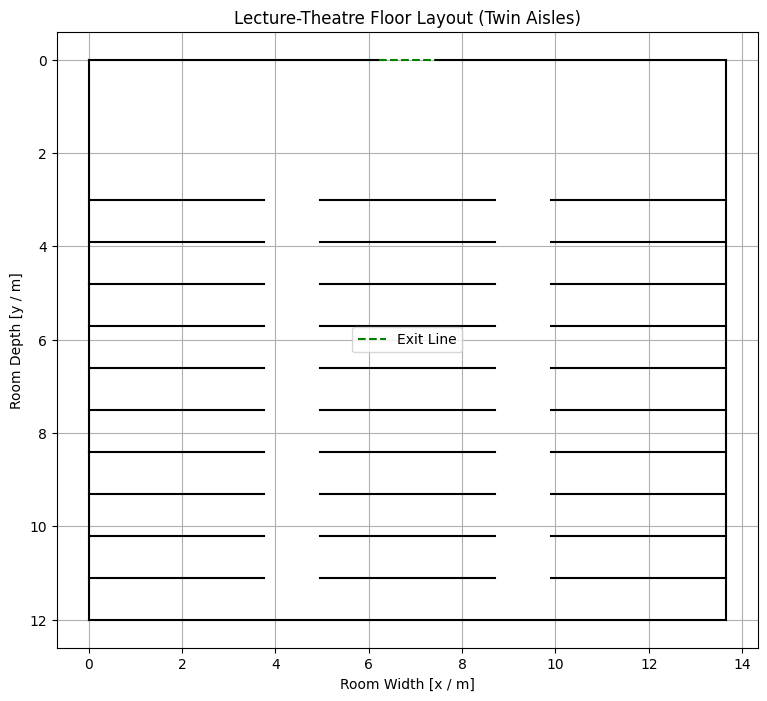

In [86]:
# 3.2 Floor Layout Visual Validation
#  modified to add aspect ratio scaling
import matplotlib.pyplot as plt

walls, exit_line = build_room_geometry(PARAMS)
fig = plt.figure(figsize=(10, 8))
for w in walls:
    plt.plot([w[0], w[2]], [w[1], w[3]], 'k-')
plt.plot([exit_line[0], exit_line[2]], [exit_line[1], exit_line[3]], 'g--', label='Exit Line')
plt.title("Lecture-Theatre Floor Layout (Twin Aisles)")
plt.xlabel("Room Width [x / m]")
plt.ylabel("Room Depth [y / m]")
plt.gca().invert_yaxis()
plt.gca().set_aspect('equal')
plt.legend()
plt.grid(True)
plt.show()

In [87]:
# 3.3 Dynamic Interaction Force Core


@njit
def compute_pair_force_scalar(dr, dv, r_i, r_j, A, B, k, kappa):
    """
    Calculates normal interaction and tangential friction force component.
    dr = x_i - x_j [m]
    dv = v_i - v_j [m/s]
    """
    dist = np.sqrt(dr[0]**2 + dr[1]**2)
    if dist == 0.0:
        return np.zeros(2)

    n = dr / dist
    t = np.array([-n[1], n[0]])

    overlap = (r_i + r_j) - dist
    f_mag = A * np.exp(overlap / B)

    if overlap > 0.0:
        f_mag += k * overlap
        f_friction = -kappa * overlap * np.dot(dv, t) * t
    else:
        f_friction = np.zeros(2)

    return f_mag * n + f_friction

@njit
def compute_wall_force_scalar(x_i, v_i, r_i, w_seg, A, B, k, kappa):
    p1 = w_seg[0:2]
    p2 = w_seg[2:4]
    line_vec = p2 - p1
    line_len = np.sqrt(line_vec[0]**2 + line_vec[1]**2)
    if line_len == 0.0:
        return np.zeros(2)
    t_wall = line_vec / line_len

    proj = np.dot(x_i - p1, t_wall)
    proj_clamped = max(0.0, min(line_len, proj))
    closest_pt = p1 + proj_clamped * t_wall

    dr = x_i - closest_pt
    d_iw = np.sqrt(dr[0]**2 + dr[1]**2)
    if d_iw == 0.0:
        return np.zeros(2)

    n_iw = dr / d_iw
    t_iw = np.array([-n_iw[1], n_iw[0]])

    overlap = r_i - d_iw
    f_mag = A * np.exp(overlap / B)

    if overlap > 0.0:
        f_mag += k * overlap
        f_friction = -kappa * overlap * np.dot(v_i, t_iw) * t_iw
    else:
        f_friction = np.zeros(2)

    return f_mag * n_iw + f_friction

In [88]:
#3.4  Agent placement, room constants and numerical settings
import time

def place_agents(params, rng, jitter=0.02):
    """All seats occupied. Random body radius (uniform) and a small random offset inside the seat [m].
    Seat centres: pitch along x, row-lane centre along y."""
    rows = int(params['rows']); num_blocks = int(params['n_aisles']) + 1; bs = int(params['block_seats'])
    pitch, rd, aw, fd = params['seat_pitch'], params['row_depth'], params['aisle_width'], params['front_depth']
    block_w = bs * pitch
    pos = []
    for r in range(rows):
        y = fd + (r + 0.5) * rd
        for b in range(num_blocks):
            b_left = b * (block_w + aw)
            for s in range(bs):
                pos.append([b_left + (s + 0.5) * pitch, y])
    pos = np.array(pos, dtype=np.float64)
    pos += rng.uniform(-jitter, jitter, pos.shape)               # random offset inside the seat
    rad = rng.uniform(params['r_min'], params['r_max'], len(pos))  # random body radius
    return pos, rad

def aisle_centres(params):
    bs, pitch, aw = int(params['block_seats']), params['seat_pitch'], params['aisle_width']
    block_w = bs * pitch
    return np.array([(a + 1) * block_w + a * aw + aw / 2.0 for a in range(int(params['n_aisles']))])

walls, exit_line = build_room_geometry(PARAMS)
AISLE_XC = aisle_centres(PARAMS)
ROOM_W = float(walls[:, 0].max())          # x extent [m]
ROOM_L = float(walls[:, 3].max())          # y extent [m]
EXIT_X = 0.5 * (exit_line[0] + exit_line[2])

D_CUT = 2.0          # pair-force cutoff on centre distance [m] (checked in 4.5)
WALL_CUT = 1.5       # wall-force cutoff on centre-to-wall distance [m] (checked in 4.5)
TURN_ZONE = 1.2      # within this distance of an aisle centre line, agents head diagonally into the aisle [m]
DT = 0.001           # default time step [s]. Speed-dependent rule: dt_for_speed() in 3.8; the evidence is in cells 4.9, 4.10 and 4.10b (full run).
NX = int(ROOM_W / D_CUT) + 1
NY = int(ROOM_L / D_CUT) + 1

# parameter vectors for the numba kernels: [m, tau, A, B, k, kappa, d_cut, wall_cut]
P_VEC = np.array([PARAMS['m'], PARAMS['tau'], PARAMS['A'], PARAMS['B'], PARAMS['k'], PARAMS['kappa'], D_CUT, WALL_CUT])
GEO = np.array([PARAMS['front_depth'], EXIT_X, -1.0, TURN_ZONE])   # [front_depth, exit_x, exit_target_y, turn_zone]

pos_demo, rad_demo = place_agents(PARAMS, np.random.default_rng(BASE_SEED))
print(f"{len(pos_demo)} agents placed; room {ROOM_W:.2f} m x {ROOM_L:.2f} m; aisle centres {AISLE_XC}")


150 agents placed; room 13.65 m x 12.00 m; aisle centres [4.35 9.3 ]


In [89]:
#3.5  Desired direction (waypoint rule)
@njit
def desired_direction(x, y, aisle_xc, front_depth, exit_x, exit_y, turn_zone):
    """Unit vector toward the current target.
    Front area (y < front_depth): head for the exit.
    Seating zone: head for the nearest aisle. Within turn_zone of the aisle centre line the target is
    1 m ahead toward the front, so agents leave the row diagonally and then walk down the aisle.
    (A pure sideways target made people from opposite sides block each other head-on at the aisle entrance.)"""
    if y < front_depth:
        tx, ty = exit_x, exit_y
    else:
        best = 0
        bd = abs(x - aisle_xc[0])
        for a in range(1, len(aisle_xc)):
            d = abs(x - aisle_xc[a])
            if d < bd:
                bd = d
                best = a
        tx = aisle_xc[best]
        if bd < turn_zone:
            ty = y - 1.0
        else:
            ty = y
    dx, dy = tx - x, ty - y
    d = np.sqrt(dx * dx + dy * dy)
    if d == 0.0:
        return 0.0, 0.0
    return dx / d, dy / d

In [90]:
# 3.6a  Reference neighbour search and wall loop (slow, uses the verified scalar kernels from 3.3)
@njit
def pair_forces_brute_ref(pos, vel, rad, active, A, B, k, kappa, d_cut, F):
    """Brute-force O(N^2) pair forces with a distance cutoff. Reference for the cell-list check."""
    n = len(pos)
    F[:, :] = 0.0
    cut2 = d_cut * d_cut
    for i in range(n):
        if not active[i]:
            continue
        for j in range(i + 1, n):
            if not active[j]:
                continue
            dr = pos[i] - pos[j]
            if dr[0] * dr[0] + dr[1] * dr[1] > cut2:
                continue
            f = compute_pair_force_scalar(dr, vel[i] - vel[j], rad[i], rad[j], A, B, k, kappa)
            F[i] += f
            F[j] -= f      # Newton's third law

@njit
def wall_forces_ref(pos, vel, rad, active, walls, A, B, k, kappa, wall_cut, F):
    F[:, :] = 0.0
    cut2 = wall_cut * wall_cut
    for i in range(len(pos)):
        if not active[i]:
            continue
        x, y = pos[i, 0], pos[i, 1]
        for w in range(len(walls)):
            dx = max(min(walls[w, 0], walls[w, 2]) - x, 0.0, x - max(walls[w, 0], walls[w, 2]))
            dy = max(min(walls[w, 1], walls[w, 3]) - y, 0.0, y - max(walls[w, 1], walls[w, 3]))
            if dx * dx + dy * dy > cut2:
                continue
            F[i] += compute_wall_force_scalar(pos[i], vel[i], rad[i], walls[w], A, B, k, kappa)


In [91]:
 #3.6b  Fast kernels (no array allocation) and cell-list neighbour search
@njit
def pair_force_fast(drx, dry, dvx, dvy, ri, rj, A, B, k, kappa):
    """Same formula as compute_pair_force_scalar, written with scalars only. dr = x_i - x_j, dv = v_i - v_j."""
    dist = np.sqrt(drx * drx + dry * dry)
    if dist == 0.0:
        return 0.0, 0.0
    nx = drx / dist; ny = dry / dist
    tx = -ny; ty = nx
    ov = ri + rj - dist
    fm = A * np.exp(ov / B)
    if ov > 0.0:
        fm += k * ov
        fr = -kappa * ov * (dvx * tx + dvy * ty)
        return fm * nx + fr * tx, fm * ny + fr * ty
    return fm * nx, fm * ny

@njit
def wall_force_fast(x, y, vx, vy, r, x1, y1, x2, y2, A, B, k, kappa):
    """Same formula as compute_wall_force_scalar, scalars only."""
    lx = x2 - x1; ly = y2 - y1
    L = np.sqrt(lx * lx + ly * ly)
    if L == 0.0:
        return 0.0, 0.0
    twx = lx / L; twy = ly / L
    proj = (x - x1) * twx + (y - y1) * twy
    proj = max(0.0, min(L, proj))
    cx = x1 + proj * twx; cy = y1 + proj * twy
    drx = x - cx; dry = y - cy
    d = np.sqrt(drx * drx + dry * dry)
    if d == 0.0:
        return 0.0, 0.0
    nx = drx / d; ny = dry / d
    tx = -ny; ty = nx
    ov = r - d
    fm = A * np.exp(ov / B)
    if ov > 0.0:
        fm += k * ov
        fr = -kappa * ov * (vx * tx + vy * ty)
        return fm * nx + fr * tx, fm * ny + fr * ty
    return fm * nx, fm * ny

@njit
def pair_forces_brute_fast(pos, vel, rad, active, A, B, k, kappa, d_cut, F):
    n = len(pos)
    F[:, :] = 0.0
    cut2 = d_cut * d_cut
    for i in range(n):
        if not active[i]:
            continue
        for j in range(i + 1, n):
            if not active[j]:
                continue
            drx = pos[i, 0] - pos[j, 0]; dry = pos[i, 1] - pos[j, 1]
            if drx * drx + dry * dry > cut2:
                continue
            fx, fy = pair_force_fast(drx, dry, vel[i, 0] - vel[j, 0], vel[i, 1] - vel[j, 1], rad[i], rad[j], A, B, k, kappa)
            F[i, 0] += fx; F[i, 1] += fy
            F[j, 0] -= fx; F[j, 1] -= fy

@njit
def pair_forces_cells(pos, vel, rad, active, A, B, k, kappa, d_cut, nx, ny, head, nxt, F):
    """Cell-list pair forces. The room is cut into square cells of side d_cut, so every neighbour within
    d_cut lies in the same or one of the 8 adjacent cells. head[c] = first agent in cell c, nxt[i] = next one."""
    n = len(pos)
    F[:, :] = 0.0
    head[:] = -1
    cut2 = d_cut * d_cut
    for i in range(n):                       # build the linked lists
        if active[i]:
            cx = min(nx - 1, max(0, int(pos[i, 0] / d_cut)))
            cy = min(ny - 1, max(0, int(pos[i, 1] / d_cut)))
            c = cy * nx + cx
            nxt[i] = head[c]
            head[c] = i
    for i in range(n):                       # search the 3x3 block of cells around each agent
        if not active[i]:
            continue
        cx = min(nx - 1, max(0, int(pos[i, 0] / d_cut)))
        cy = min(ny - 1, max(0, int(pos[i, 1] / d_cut)))
        for ddx in range(-1, 2):
            for ddy in range(-1, 2):
                ncx = cx + ddx; ncy = cy + ddy
                if ncx < 0 or ncx >= nx or ncy < 0 or ncy >= ny:
                    continue
                j = head[ncy * nx + ncx]
                while j != -1:
                    if j > i:                # each pair once
                        drx = pos[i, 0] - pos[j, 0]; dry = pos[i, 1] - pos[j, 1]
                        if drx * drx + dry * dry <= cut2:
                            fx, fy = pair_force_fast(drx, dry, vel[i, 0] - vel[j, 0], vel[i, 1] - vel[j, 1], rad[i], rad[j], A, B, k, kappa)
                            F[i, 0] += fx; F[i, 1] += fy
                            F[j, 0] -= fx; F[j, 1] -= fy
                    j = nxt[j]

@njit
def wall_forces_fast(pos, vel, rad, active, walls, A, B, k, kappa, wall_cut, F):
    """Adds wall forces to F (does not zero it). Walls farther than wall_cut are skipped by a bounding-box test."""
    cut2 = wall_cut * wall_cut
    for i in range(len(pos)):
        if not active[i]:
            continue
        x = pos[i, 0]; y = pos[i, 1]
        for w in range(len(walls)):
            x1 = walls[w, 0]; y1 = walls[w, 1]; x2 = walls[w, 2]; y2 = walls[w, 3]
            dx = max(min(x1, x2) - x, 0.0, x - max(x1, x2))
            dy = max(min(y1, y2) - y, 0.0, y - max(y1, y2))
            if dx * dx + dy * dy > cut2:
                continue
            fx, fy = wall_force_fast(x, y, vel[i, 0], vel[i, 1], rad[i], x1, y1, x2, y2, A, B, k, kappa)
            F[i, 0] += fx; F[i, 1] += fy


In [92]:
#3.6c  Circular pillar: force from a circular obstacle (same force law as the walls, computed once on the circle)
@njit
def circle_force_fast(x, y, vx, vy, r, cx, cy, R, A, B, k, kappa):
    """Force on an agent (centre x,y; radius r) from a circular pillar (centre cx,cy; radius R).
    d = distance from the agent centre to the pillar SURFACE; same form as the wall force (Eq. 3)."""
    drx = x - cx; dry = y - cy
    dc = np.sqrt(drx * drx + dry * dry)
    if dc == 0.0:
        return 0.0, 0.0
    d = dc - R
    nx = drx / dc; ny = dry / dc
    tx = -ny; ty = nx
    ov = r - d
    fm = A * np.exp(ov / B)
    if ov > 0.0:
        fm += k * ov
        fr = -kappa * ov * (vx * tx + vy * ty)
        return fm * nx + fr * tx, fm * ny + fr * ty
    return fm * nx, fm * ny

@njit
def obstacle_forces_fast(pos, vel, rad, active, obst, A, B, k, kappa, cut, F):
    """Adds the forces of all circular pillars (rows of obst: cx, cy, R) to F."""
    for i in range(len(pos)):
        if not active[i]:
            continue
        for o in range(len(obst)):
            dx = pos[i, 0] - obst[o, 0]; dy = pos[i, 1] - obst[o, 1]
            if np.sqrt(dx * dx + dy * dy) - obst[o, 2] > cut:
                continue
            fx, fy = circle_force_fast(pos[i, 0], pos[i, 1], vel[i, 0], vel[i, 1], rad[i],
                                       obst[o, 0], obst[o, 1], obst[o, 2], A, B, k, kappa)
            F[i, 0] += fx; F[i, 1] += fy


In [93]:
#3.7  Acceleration, main time loop (velocity Verlet) and a run wrapper

@njit
def accel_fast(pos, vel, rad, active, v0, walls, obst, aisle_xc, geo, P, use_cells, nx, ny, head, nxt, F, acc):
    m, tau, A, B, k, kappa, d_cut, wall_cut = P[0], P[1], P[2], P[3], P[4], P[5], P[6], P[7]
    front_depth, exit_x, exit_y, turn_zone = geo[0], geo[1], geo[2], geo[3]
    if use_cells:
        pair_forces_cells(pos, vel, rad, active, A, B, k, kappa, d_cut, nx, ny, head, nxt, F)
    else:
        pair_forces_brute_fast(pos, vel, rad, active, A, B, k, kappa, d_cut, F)
    wall_forces_fast(pos, vel, rad, active, walls, A, B, k, kappa, wall_cut, F)
    obstacle_forces_fast(pos, vel, rad, active, obst, A, B, k, kappa, wall_cut, F)
    for i in range(len(pos)):
        if active[i]:
            ex, ey = desired_direction(pos[i, 0], pos[i, 1], aisle_xc, front_depth, exit_x, exit_y, turn_zone)
            acc[i, 0] = (m * (v0 * ex - vel[i, 0]) / tau + F[i, 0]) / m
            acc[i, 1] = (m * (v0 * ey - vel[i, 1]) / tau + F[i, 1]) / m
        else:
            acc[i, 0] = 0.0
            acc[i, 1] = 0.0

@njit
def run_core_fast(pos0, rad, v0, dt, T_max, walls, obst, aisle_xc, geo, P, use_cells, nx, ny, rec_every):
    """Velocity Verlet for the whole crowd. An agent is removed when its centre crosses y = 0 (the exit line).
    Returns exit times, people-out history, conservation flag, steps done, final pos, vel, active flags."""
    n = len(pos0)
    pos = pos0.copy()
    vel = np.zeros_like(pos)
    active = np.ones(n, dtype=np.bool_)
    t_exit = np.full(n, np.nan)
    F = np.zeros_like(pos); acc = np.zeros_like(pos); acc_new = np.zeros_like(pos)
    head = np.full(nx * ny, -1, dtype=np.int64); nxt = np.full(n, -1, dtype=np.int64)
    max_steps = int(T_max / dt)
    out_hist = np.zeros(max_steps // rec_every + 2, dtype=np.int64)
    n_rec = 0; n_out = 0; cons_ok = True
    accel_fast(pos, vel, rad, active, v0, walls, obst, aisle_xc, geo, P, use_cells, nx, ny, head, nxt, F, acc)
    steps_done = 0
    for step in range(max_steps):
        t = (step + 1) * dt
        pos_new = pos + vel * dt + 0.5 * acc * dt * dt          # position update
        v_pred = vel + acc * dt                                   # predicted velocity (forces depend on velocity)
        accel_fast(pos_new, v_pred, rad, active, v0, walls, obst, aisle_xc, geo, P, use_cells, nx, ny, head, nxt, F, acc_new)
        vel = vel + 0.5 * (acc + acc_new) * dt                    # velocity update
        pos = pos_new
        acc = acc_new.copy()
        n_active = 0
        for i in range(n):
            if active[i]:
                if pos[i, 1] < 0.0:                               # crossed the exit line
                    active[i] = False
                    t_exit[i] = t
                    n_out += 1
                    vel[i, 0] = 0.0; vel[i, 1] = 0.0; acc[i, 0] = 0.0; acc[i, 1] = 0.0
                else:
                    n_active += 1
        if n_active + n_out != n:                                 # conservation of people
            cons_ok = False
        if step % rec_every == 0:
            out_hist[n_rec] = n_out
            n_rec += 1
        steps_done = step + 1
        if n_out == n:
            break
    return t_exit, out_hist[:n_rec], cons_ok, steps_done, pos, vel, active

NO_OBST = np.zeros((0, 3))      # no pillar

def run_evacuation(v0, seed, dt=DT, T_max=400.0, use_cells=True, rec_every=100, pos0=None, rad=None, obst=None):
    """One evacuation run. Returns a dict. evac_time is NaN if not everybody left within T_max
    or if any agent ended outside the room (tunnelling through a wall)."""
    obst = NO_OBST if obst is None else obst
    if pos0 is None:
        pos0, rad = place_agents(PARAMS, np.random.default_rng(seed))
    t_exit, hist, cons, steps, pos_end, vel_end, active = run_core_fast(
        pos0, rad, v0, dt, T_max, walls, obst, AISLE_XC, GEO, P_VEC, use_cells, NX, NY, rec_every)
    outside = active & ((pos_end[:, 0] < 0) | (pos_end[:, 0] > ROOM_W) | (pos_end[:, 1] > ROOM_L))
    all_out = not active.any()
    ok = all_out and cons and not outside.any()
    return dict(evac_time=(np.nanmax(t_exit) if ok else np.nan), n_out=int((~active).sum()), conserved=cons,
                tunnelled=int(outside.sum()), steps=steps, t_exit=t_exit, out_hist=hist,
                pos_end=pos_end, vel_end=vel_end, active=active)

_ = run_evacuation(PARAMS['v0'], BASE_SEED, T_max=1.0)    # compile once
print("Crowd simulation compiled.")



Crowd simulation compiled.


In [94]:
#3.8  Replications, 95% confidence intervals, time-step rule and a parallel batch runner
from scipy import stats
from numba import prange

def dt_for_speed(v0):
    """Time step [s] as a function of desired speed. 0.001 s up to 5 m/s, 0.0005 s above. Evidence: trajectory error and
    mean evacuation time against dt (cells 4.9 and 4.10), and the number of runs lost to wall tunnelling for each dt
    at 5, 7 and 10 m/s (cell 4.10b, full run), which is printed there rather than quoted here."""
    return 0.001 if v0 <= 5.0 else 0.0005

def mean_ci(x, level=0.95):
    """Mean and half-width of the two-sided confidence interval (Student t, because the number of seeds is small)."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    if n == 0:
        return np.nan, np.nan
    if n == 1:
        return float(x[0]), np.nan
    half = stats.t.ppf(0.5 + level / 2.0, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return float(x.mean()), float(half)

@njit(parallel=True)
def run_batch_core(pos0_all, rad_all, v0, dt, T_max, walls, obst, aisle_xc, geo, P, nx, ny, room_w, room_l):
    """Runs one evacuation per seed in parallel (prange). Same simulation code as run_core_fast, brute-force neighbours."""
    S = pos0_all.shape[0]
    evac = np.full(S, np.nan)
    n_out = np.zeros(S, dtype=np.int64)
    cons = np.ones(S, dtype=np.bool_)
    tun = np.zeros(S, dtype=np.int64)
    for s in prange(S):
        t_exit, hist, c, steps, pe, ve, act = run_core_fast(pos0_all[s], rad_all[s], v0, dt, T_max, walls, obst, aisle_xc,
                                                             geo, P, False, nx, ny, 1000)
        n = len(act)
        k_out = 0
        k_tun = 0
        t_last = 0.0
        for i in range(n):
            if not act[i]:
                k_out += 1
                if t_exit[i] > t_last:
                    t_last = t_exit[i]
            elif pe[i, 0] < 0.0 or pe[i, 0] > room_w or pe[i, 1] > room_l:
                k_tun += 1
        n_out[s] = k_out
        cons[s] = c
        tun[s] = k_tun
        if k_out == n and c and k_tun == 0:
            evac[s] = t_last
    return evac, n_out, cons, tun

def replicate(v0, seeds, dt=None, T_max=400.0, parallel=True, level=0.95, obst=None):
    """Monte Carlo replications of the evacuation at one desired speed. Seed s fixes the seat offsets and body radii
    (the same seeds are reused for every speed: common random numbers, so curves differ by physics, not by luck).
    Runs that do not end with everybody out (stuck, tunnelled) are counted as failed and excluded from the mean."""
    dt = dt_for_speed(v0) if dt is None else dt
    obst = NO_OBST if obst is None else obst
    seeds = list(seeds)
    pos_all = np.empty((len(seeds), len(pos_demo), 2)); rad_all = np.empty((len(seeds), len(pos_demo)))
    for j, s in enumerate(seeds):
        pos_all[j], rad_all[j] = place_agents(PARAMS, np.random.default_rng(s))
    if parallel:
        evac, n_out, cons, tun = run_batch_core(pos_all, rad_all, v0, dt, T_max, walls, obst, AISLE_XC, GEO, P_VEC,
                                                NX, NY, ROOM_W, ROOM_L)
    else:
        evac = np.array([run_evacuation(v0, s, dt=dt, T_max=T_max, use_cells=False, pos0=pos_all[j], rad=rad_all[j],
                                        obst=obst)['evac_time'] for j, s in enumerate(seeds)])
    valid = evac[np.isfinite(evac)]
    mean, half = mean_ci(valid, level)
    return dict(v0=v0, dt=dt, n_seeds=len(seeds), n_valid=len(valid), n_failed=len(seeds) - len(valid),
                mean=mean, ci_half=half, sd=float(valid.std(ddof=1)) if len(valid) > 1 else np.nan, times=evac)

def sweep(speeds, seeds, dt_rule=dt_for_speed, parallel=True, verbose=True, obst=None):
    rows = []
    for v0 in speeds:
        t0 = time.perf_counter()
        r = replicate(v0, seeds, dt=dt_rule(v0) if dt_rule else None, parallel=parallel, obst=obst)
        rows.append(r)
        if verbose:
            print(f"v0 = {v0:4.1f} m/s (dt = {r['dt']}): mean = {r['mean']:6.1f} +/- {r['ci_half']:4.1f} s (95% CI), "
                  f"valid {r['n_valid']}/{r['n_seeds']}, {time.perf_counter() - t0:.1f} s")
    return rows

def plot_sweep(rows, label, ax=None, **kw):
    ax = plt.gca() if ax is None else ax
    v = [r['v0'] for r in rows]; m = [r['mean'] for r in rows]; h = [r['ci_half'] for r in rows]
    ax.errorbar(v, m, yerr=h, fmt='o-', capsize=3, label=label, **kw)
    ax.set_xlabel('desired speed $v_0$ [m/s]'); ax.set_ylabel('evacuation time [s]'); ax.grid(True, alpha=0.3)
    return ax

_ = replicate(3.0, [BASE_SEED], T_max=1.0)       # compile once
print("Replication machinery compiled.")



Replication machinery compiled.


In [95]:
#3.9  Pillar obstacle in front of the exit
def make_pillar(dist=None, radius=None, x_offset=0.0):
    """One circular pillar in the front area, `dist` m in front of the exit line (y = 0), `x_offset` m beside the exit centre.
    Returns an array with one row (cx, cy, R) in metres."""
    dist = PARAMS['obstacle_dist'] if dist is None else dist
    radius = PARAMS['obstacle_radius'] if radius is None else radius
    assert radius + 0.3 < dist < PARAMS['front_depth'] - radius - 0.3, "Pillar must stand clear of the exit wall and the seating"
    return np.array([[EXIT_X + x_offset, dist, radius]])

pillar_default = make_pillar()
print(f"default pillar: centre ({pillar_default[0,0]:.2f}, {pillar_default[0,1]:.2f}) m, radius {pillar_default[0,2]} m")
_ = replicate(3.0, [BASE_SEED], T_max=1.0, obst=pillar_default)       # compile once with an obstacle

default pillar: centre (6.83, 1.50) m, radius 0.3 m


## 4. Verification

### Explanation of Verification Checks
This section verifies that our core physical interaction forces adhere strictly to Newtonian physics and Helbing's social force equations:
1. **Newton's Third Law (Reciprocity)**: Asserts that $\mathbf{f}_{ij} = -\mathbf{f}_{ji}$. If this failed, momentum would not be conserved in collisions, causing agents to self-accelerate.
2. **Friction Vector Alignment**: Verifies that the tangential friction component actively opposes the relative sliding velocity vector (meaning the dot product of the friction force and relative tangential sliding velocity is negative). If this failed, friction would artificially speed up sliding agents rather than dissipating energy.
3. **Frictional Coefficient Impact ($\kappa$-dependence)**: Asserts that removing sliding friction (setting $\kappa = 0$) returns a numerically different output force than $\kappa > 0$. If this failed, it would indicate that our friction parameters have no mechanical effect on the contact dynamics.

*Note: cells 4.1 to 4.3 test the pair force, the wall force and the integrator. Cells 4.4 to 4.11 then test the whole simulation: initial overlaps, neighbour search, conservation, the time step, the statistics code and the pillar.*

In [96]:
# 4.1 Force Reciprocity and Friction Direction Verification
#  modified to perform strict projection validations

dr = np.array([0.4, 0.0])
dv = np.array([0.1, 0.5])

A, B, k, kappa = 2000.0, 0.08, 1.2e5, 2.4e5
r_i, r_j = 0.25, 0.25

f_ij = compute_pair_force_scalar(dr, dv, r_i, r_j, A, B, k, kappa)
f_ji = compute_pair_force_scalar(-dr, -dv, r_i, r_j, A, B, k, kappa)

# 1. Reciprocity validation
assert np.allclose(f_ij, -f_ji), "Error: Reciprocity violated!"

# 2. Friction opposition validation
t_ij = np.array([0.0, 1.0])
sliding_v = np.dot(dv, t_ij)
assert np.dot(f_ij, t_ij) * sliding_v < 0.0, "Error: Friction does not oppose sliding!"

# 3. Kappa dependence validation
f_no_kappa = compute_pair_force_scalar(dr, dv, r_i, r_j, A, B, k, 0.0)
assert not np.allclose(f_ij, f_no_kappa), "Error: Friction has no impact on total output force!"

print("VERIFICATION: Reciprocity, Friction Vector Alignment, and Kappa Influence -> PASS")

VERIFICATION: Reciprocity, Friction Vector Alignment, and Kappa Influence -> PASS


### 4.2 Single Agent Target Drive
This check simulates a single isolated agent accelerating from rest toward a fixed direction under the target driving force. It compares the numerical velocity path at $t = 1.0\text{ s}$ against the closed-form analytical solution $v(t) = v_0 (1 - e^{-t/\tau})$ over a sequence of refined time-step sizes $\Delta t$.

* **What this proves**: It confirms the mathematical correctness of our Velocity Verlet integration step and checks that the numerical solution converges toward the exact analytical limit as $\Delta t \to 0$.
* **What goes wrong if it fails**: A failure indicates coding bugs in the integration updates (such as mismatched time indices, incorrect prediction step velocity dependencies, or inaccurate forces), leading to energy artificial generation, numerical instability, or inconsistent solver accuracy.

In [97]:
# 4.2 Single Agent Target Drive Verification
# Unit test: velocity-Verlet convergence to the analytical solution v(t) = v0*(1 - exp(-t/tau))
import numpy as np

tau = PARAMS['tau']   # relaxation time [s]
v0 = PARAMS['v0']     # desired speed [m/s]

def simulate_single_agent(dt, total_time=1.0):
    """One agent, driving force only (no walls, no neighbours). Returns the velocity [m/s] at total_time."""
    steps = int(round(total_time / dt))
    x = np.array([0.0, 0.0])      # position [m]
    v = np.array([0.0, 0.0])      # velocity [m/s]
    e_i = np.array([1.0, 0.0])    # desired direction (unit vector)

    # Velocity Verlet for a single agent
    for _ in range(steps):
        a = (v0 * e_i - v) / tau                    # acceleration at time t
        x_next = x + v * dt + 0.5 * a * (dt**2)     # position update
        v_pred = v + a * dt                         # predicted velocity (force depends on velocity)
        a_next = (v0 * e_i - v_pred) / tau          # acceleration at t + dt
        v_next = v + 0.5 * (a + a_next) * dt        # velocity update
        x, v = x_next, v_next
    return v[0]

# Analytical velocity at t = 1.0 s
t_end = 1.0
v_analytical = v0 * (1.0 - np.exp(-t_end / tau))

# Test with several time steps to observe convergence of the error
dts = [0.1, 0.05, 0.02, 0.01]
errors = []
for dt in dts:
    v_sim = simulate_single_agent(dt, total_time=t_end)
    errors.append(abs(v_sim - v_analytical))

# Empirical order of accuracy between consecutive steps: log(E1/E2) / log(dt1/dt2)
orders = []
for i in range(len(errors) - 1):
    orders.append(np.log(errors[i] / errors[i + 1]) / np.log(dts[i] / dts[i + 1]))

print(f"Errors: {errors}")
print(f"Empirical Orders of Accuracy: {orders}")

# Checks: error shrinks, is small at the finest dt, and the order is close to 2
assert errors[-1] < errors[0], "Error: Convergence check failed; error does not decrease with dt!"
assert errors[-1] < 1e-4, "Error: Error too large at the finest time step!"
assert all(1.8 < o < 2.2 for o in orders), "Error: Unexpected order of accuracy!"
print("VERIFICATION: Single Agent Target Drive Convergence -> PASS")

Errors: [np.float64(0.0031691221490219856), np.float64(0.0007307613982074912), np.float64(0.00011159887533951363), np.float64(2.7478169605243963e-05)]
Empirical Orders of Accuracy: [np.float64(2.1166109352265217), np.float64(2.050851290059602), np.float64(2.021964677512317)]
VERIFICATION: Single Agent Target Drive Convergence -> PASS


### 4.3 Wall Standoff and Friction Verification
This section tests both sliding wall friction and the normal boundary standoff balance through two distinct checks:
1. **Sliding Friction Opposition**: Initiates an agent moving parallel to a flat wall segment. It asserts that the resulting wall friction force points opposite to the agent's relative sliding velocity vector.
2. **Dynamic Equilibrium Standoff Gap**: Simulates an agent driven directly orthogonal into a rigid wall boundary. As the agent settles, the normal repulsive force balances the driving force. It compares this final settled gap to the analytical equilibrium limit: $d_{\text{gap}} = -B \ln\left(\frac{m v_0}{\tau A}\right)$.

* **What this proves**: It ensures that boundary-sliding friction properly dissipates tangential kinetic energy and that normal social-force boundary interactions balance exactly at the expected theoretical distances.
* **What goes wrong if it fails**: If the friction check fails, sliding agents would experience self-acceleration along walls (violating thermodynamic limits). If the standoff check fails, agents would either completely clip through solid boundaries or stand off at physically non-compliant distances.

In [98]:
# 4.3 Wall Standoff Verification
# unit test verifying physical standoff distance analytical limits and sliding friction opposition
import numpy as np

mass = PARAMS['m']
tau = PARAMS['tau']
v0 = PARAMS['v0']
A = PARAMS['A']
B = PARAMS['B']
k = PARAMS['k']
kappa = PARAMS['kappa']

# --- 1. Sliding Friction Vector Opposition Check ---
# Pedestrian moves parallel to a horizontal wall located at y = 0
x_sliding = np.array([1.0, 0.25])  # Overlaps since r = 0.3 and y = 0.25 < 0.3
v_sliding = np.array([1.5, -0.1])  # Moving right (tangent component) and down
r_sliding = 0.3
w_seg_sliding = np.array([0.0, 0.0, 2.0, 0.0]) # Wall segment

f_wall_sliding = compute_wall_force_scalar(x_sliding, v_sliding, r_sliding, w_seg_sliding, A, B, k, kappa)

# Tangent vector for wall at y=0 is along the x-axis: [1.0, 0.0]
# Friction must oppose sliding velocity along this tangent direction
assert f_wall_sliding[0] * v_sliding[0] < 0.0, "Error: Wall sliding friction does not oppose lateral velocity!"
print("VERIFICATION: Wall Friction Opposition -> PASS")

# --- 2. Dynamic Equilibrium Standoff Gap Check ---
# Dynamic balance of driving force and normal boundary repulsion at contact equilibrium:
# m * v0 / tau = A * exp((r_i - d_iw) / B)
# Standoff gap (d_iw - r_i) matches the analytical prediction:
expected_gap = -B * np.log((mass * v0) / (tau * A))

# Numerical simulation to check where an agent settles when pushed directly against a flat wall
dt = 0.005
total_time = 30.0
steps = int(total_time / dt)

x_i = np.array([1.0, 1.0])
v_i = np.array([0.0, 0.0])
r_i = 0.3
w_seg = np.array([0.0, 0.0, 2.0, 0.0])  # Wall at y = 0

# Drive agent straight down towards the wall at y = 0
for _ in range(steps):
    # Desired drive points straight down (e_y = -1)
    f_des = mass * (v0 * np.array([0.0, -1.0]) - v_i) / tau

    # Wall force interaction
    f_wall = compute_wall_force_scalar(x_i, v_i, r_i, w_seg, A, B, k, kappa)

    # Verlet Step
    a = (f_des + f_wall) / mass
    x_next = x_i + v_i * dt + 0.5 * a * (dt**2)

    v_pred = v_i + a * dt
    f_des_next = mass * (v0 * np.array([0.0, -1.0]) - v_pred) / tau
    f_wall_next = compute_wall_force_scalar(x_next, v_pred, r_i, w_seg, A, B, k, kappa)
    a_next = (f_des_next + f_wall_next) / mass

    v_next = v_i + 0.5 * (a + a_next) * dt

    x_i = x_next
    v_i = v_next

simulated_gap = x_i[1] - r_i
print(f"Expected Gap: {expected_gap:.6f} m")
print(f"Simulated Gap: {simulated_gap:.6f} m")

assert np.allclose(simulated_gap, expected_gap, rtol=1e-3), "Error: Simulated wall standoff gap does not match physical expectation!"
print("VERIFICATION: Wall Standoff Stiff Boundary Balance -> PASS")

VERIFICATION: Wall Friction Opposition -> PASS
Expected Gap: 0.169621 m
Simulated Gap: 0.169621 m
VERIFICATION: Wall Standoff Stiff Boundary Balance -> PASS


In [99]:
#4.4  Verification: zero overlap at t = 0 (markdown above it: what it proves, what fails if it does not)
pos0, rad0 = place_agents(PARAMS, np.random.default_rng(BASE_SEED))
d = np.linalg.norm(pos0[:, None] - pos0[None, :], axis=2)
np.fill_diagonal(d, np.inf)
min_pair_gap = (d - (rad0[:, None] + rad0[None, :])).min()           # centre distance - sum of radii [m]

min_wall_gap = np.inf
for i in range(len(pos0)):
    for w in walls:
        p1, p2 = w[:2], w[2:]
        tvec = p2 - p1
        s = np.clip(np.dot(pos0[i] - p1, tvec) / np.dot(tvec, tvec), 0.0, 1.0)
        min_wall_gap = min(min_wall_gap, np.linalg.norm(pos0[i] - (p1 + s * tvec)) - rad0[i])

F0 = np.zeros_like(pos0); act0 = np.ones(len(pos0), dtype=np.bool_)
pair_forces_brute_ref(pos0, np.zeros_like(pos0), rad0, act0, P_VEC[2], P_VEC[3], P_VEC[4], P_VEC[5], D_CUT, F0)
Fw0 = np.zeros_like(pos0)
wall_forces_ref(pos0, np.zeros_like(pos0), rad0, act0, walls, P_VEC[2], P_VEC[3], P_VEC[4], P_VEC[5], WALL_CUT, Fw0)
print(f"min agent-agent gap = {min_pair_gap:.4f} m, min agent-wall gap = {min_wall_gap:.4f} m")
print(f"largest initial pair force = {np.linalg.norm(F0, axis=1).max():.0f} N, largest initial wall force = {np.linalg.norm(Fw0, axis=1).max():.0f} N")
assert len(pos0) == PARAMS['seats_per_row'] * PARAMS['rows'], "Wrong number of agents!"
assert min_pair_gap > 0.0, "Agents overlap each other at t = 0!"
assert min_wall_gap > 0.0, "An agent overlaps a wall at t = 0!"
print("VERIFICATION: No overlaps at t = 0 -> PASS")

min agent-agent gap = 0.0424 m, min agent-wall gap = 0.0243 m
largest initial pair force = 858 N, largest initial wall force = 1481 N
VERIFICATION: No overlaps at t = 0 -> PASS


In [100]:
#4.5  Verification: cell lists vs brute force, fast kernels vs reference, cutoff truncation
# Take a crowded mid-evacuation state (20 s into a run) and compare the force calculations on it.
res = run_evacuation(1.5, BASE_SEED, T_max=20.0)
pos_s, vel_s, act_s = res['pos_end'], res['vel_end'], res['active']
A_, B_, k_, kap_ = P_VEC[2], P_VEC[3], P_VEC[4], P_VEC[5]
n_s = len(pos_s)
F_ref = np.zeros((n_s, 2)); F_fb = np.zeros((n_s, 2)); F_cl = np.zeros((n_s, 2)); F_far = np.zeros((n_s, 2))
head_ = np.full(NX * NY, -1, dtype=np.int64); nxt_ = np.full(n_s, -1, dtype=np.int64)
rad_s = place_agents(PARAMS, np.random.default_rng(BASE_SEED))[1]     # same radii as the run above
pair_forces_brute_ref(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, F_ref)
pair_forces_brute_fast(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, F_fb)
pair_forces_cells(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, NX, NY, head_, nxt_, F_cl)
pair_forces_brute_ref(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, 6.0, F_far)       # almost no cutoff

err_cells = np.abs(F_ref - F_cl).max()
err_fast = np.abs(F_ref - F_fb).max()
err_cut = np.abs(F_ref - F_far).max()
print(f"agents still inside: {int(act_s.sum())}, largest pair force: {np.abs(F_ref).max():.0f} N")
print(f"max |brute(reference) - cell list|   = {err_cells:.2e} N")
print(f"max |brute(reference) - fast brute|  = {err_fast:.2e} N")
print(f"max effect of the {D_CUT} m cutoff (vs 6 m)  = {err_cut:.2e} N")

W_ref = np.zeros((n_s, 2)); W_fast = np.zeros((n_s, 2)); W_all = np.zeros((n_s, 2))
wall_forces_ref(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_ref)
wall_forces_fast(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_fast)
wall_forces_ref(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, 1e9, W_all)
err_wall = np.abs(W_ref - W_fast).max()
err_wcut = np.abs(W_ref - W_all).max()
print(f"max |wall reference - wall fast| = {err_wall:.2e} N;  effect of the {WALL_CUT} m wall cutoff = {err_wcut:.2e} N")

assert err_cells < 1e-9, "Cell list disagrees with brute force!"
assert err_fast < 1e-9, "Fast pair kernel disagrees with the reference kernel!"
assert err_wall < 1e-9, "Fast wall kernel disagrees with the reference kernel!"
assert err_cut < 1e-2 and err_wcut < 1e-2, "Cutoff removes a non-negligible force!"

# Whole-trajectory agreement over a short horizon. (Over a full evacuation the two runs drift apart because
# the dynamics are chaotic and the two summation orders differ in the last digits; see cell 4.7.)
ra = run_evacuation(1.5, BASE_SEED, T_max=5.0, use_cells=True)
rb = run_evacuation(1.5, BASE_SEED, T_max=5.0, use_cells=False)
traj_diff = np.abs(ra['pos_end'] - rb['pos_end']).max()
print(f"max position difference after 5 s, cells vs brute force = {traj_diff:.2e} m")
assert traj_diff < 1e-9, "Cell-list and brute-force trajectories differ early on!"
print("VERIFICATION: Cell list = brute force, fast kernels = reference, cutoffs negligible -> PASS")

agents still inside: 129, largest pair force: 1094 N
max |brute(reference) - cell list|   = 2.27e-13 N
max |brute(reference) - fast brute|  = 0.00e+00 N
max effect of the 2.0 m cutoff (vs 6 m)  = 1.25e-04 N
max |wall reference - wall fast| = 0.00e+00 N;  effect of the 1.5 m wall cutoff = 1.19e-03 N
max position difference after 5 s, cells vs brute force = 7.66e-13 m
VERIFICATION: Cell list = brute force, fast kernels = reference, cutoffs negligible -> PASS


In [101]:
#4.6  Verification: conservation of people and complete evacuation at a normal speed
res = run_evacuation(1.5, BASE_SEED, T_max=400.0)
out_hist = res['out_hist']
print(f"people out: {res['n_out']}/150, evacuation time = {res['evac_time']:.1f} s, steps = {res['steps']}")
print(f"conservation held at every step: {res['conserved']}, agents outside the room: {res['tunnelled']}")
assert res['conserved'], "People were created or lost: inside + outside != total!"
assert res['n_out'] == 150, "Not everybody left the room within T_max!"
assert res['tunnelled'] == 0, "An agent escaped through a wall!"
assert np.all(np.diff(out_hist) >= 0), "Number of people out decreased over time!"
assert np.all(res['t_exit'] > 0.0), "Invalid exit time!"
print("VERIFICATION: Conservation of people, everybody evacuates -> PASS")


people out: 150/150, evacuation time = 104.7 s, steps = 104738
conservation held at every step: True, agents outside the room: 0
VERIFICATION: Conservation of people, everybody evacuates -> PASS


In [102]:
#4.7  Performance (step 5): cost of one force evaluation and of one full run
def time_force_eval(fn, reps=300):
    fn()                                  # warm up
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps * 1e6      # microseconds

def eval_ref():
    pair_forces_brute_ref(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, F_ref)
    wall_forces_ref(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_ref)
def eval_fast_brute():
    pair_forces_brute_fast(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, F_fb)
    W_fast[:] = 0.0
    wall_forces_fast(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_fast)
def eval_fast_cells():
    pair_forces_cells(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, NX, NY, head_, nxt_, F_cl)
    W_fast[:] = 0.0
    wall_forces_fast(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_fast)

t_ref = time_force_eval(eval_ref); t_fb = time_force_eval(eval_fast_brute); t_fc = time_force_eval(eval_fast_cells)
print(f"one force evaluation (crowded state, {int(act_s.sum())} agents inside):")
print(f"  reference kernels (arrays allocated)  : {t_ref:8.1f} us")
print(f"  fast kernels, brute-force neighbours  : {t_fb:8.1f} us   ({t_ref / t_fb:.1f}x faster than reference)")
print(f"  fast kernels, cell-list neighbours    : {t_fc:8.1f} us   ({t_ref / t_fc:.1f}x faster than reference)")

t0 = time.perf_counter(); r1 = run_evacuation(1.5, BASE_SEED, use_cells=True);  w_cells = time.perf_counter() - t0
t0 = time.perf_counter(); r2 = run_evacuation(1.5, BASE_SEED, use_cells=False); w_brute = time.perf_counter() - t0
print(f"one full evacuation (v0 = 1.5 m/s, dt = {DT} s, {r1['steps']} steps): cells {w_cells:.2f} s, brute force {w_brute:.2f} s")
print(f"evacuation time, one seed: cells {r1['evac_time']:.1f} s vs brute force {r2['evac_time']:.1f} s")
print("(A single seed differs because tiny rounding differences grow exponentially in this chaotic system.")
print(" What must agree is the statistics over many seeds:)")
N_PERF = 8 if FULL_RUN else 3
ev_c = np.array([run_evacuation(1.5, 100 + s, use_cells=True)['evac_time'] for s in range(N_PERF)])
ev_b = np.array([run_evacuation(1.5, 100 + s, use_cells=False)['evac_time'] for s in range(N_PERF)])
print(f"mean over {N_PERF} seeds: cells {ev_c.mean():.1f} s, brute force {ev_b.mean():.1f} s "
      f"(standard deviations {ev_c.std(ddof=1):.1f} / {ev_b.std(ddof=1):.1f} s)")
se = np.sqrt(ev_c.var(ddof=1) / N_PERF + ev_b.var(ddof=1) / N_PERF)
assert abs(ev_c.mean() - ev_b.mean()) < 3 * se, "The two neighbour searches give different statistics!"
print("VERIFICATION: Same statistics with both neighbour searches -> PASS")


one force evaluation (crowded state, 129 agents inside):
  reference kernels (arrays allocated)  :   1231.3 us
  fast kernels, brute-force neighbours  :     95.6 us   (12.9x faster than reference)
  fast kernels, cell-list neighbours    :     88.2 us   (14.0x faster than reference)
one full evacuation (v0 = 1.5 m/s, dt = 0.001 s, 104738 steps): cells 6.68 s, brute force 5.57 s
evacuation time, one seed: cells 104.7 s vs brute force 101.1 s
(A single seed differs because tiny rounding differences grow exponentially in this chaotic system.
 What must agree is the statistics over many seeds:)
mean over 3 seeds: cells 100.1 s, brute force 99.5 s (standard deviations 1.9 / 3.9 s)
VERIFICATION: Same statistics with both neighbour searches -> PASS


In [103]:
# 4.8  Verification: the confidence-interval code and the parallel runner
# (a) Coverage test on synthetic data with a KNOWN mean: a 95% interval should contain the truth about 95% of the time.
rng_cov = np.random.default_rng(BASE_SEED)
true_mean, true_sd, n_rep, n_trials = 100.0, 5.0, 10, 4000
hits = 0
for _ in range(n_trials):
    m_, h_ = mean_ci(rng_cov.normal(true_mean, true_sd, n_rep))
    hits += (abs(m_ - true_mean) <= h_)
coverage = hits / n_trials
print(f"CI coverage on synthetic data: {coverage:.3f} (target 0.950, n = {n_rep} per interval, {n_trials} intervals)")
assert abs(coverage - 0.95) < 0.015, "The confidence interval does not have the intended coverage!"
print("VERIFICATION: 95% confidence intervals have ~95% coverage -> PASS")

# (b) The parallel batch must give exactly the same evacuation times as the serial runs (same seeds, same code path).
seeds_chk = [BASE_SEED, BASE_SEED + 1, BASE_SEED + 2]
t0 = time.perf_counter(); r_par = replicate(3.0, seeds_chk, parallel=True);  t_par_chk = time.perf_counter() - t0   # timings are reused in 5.14
t0 = time.perf_counter(); r_ser = replicate(3.0, seeds_chk, parallel=False); t_ser_chk = time.perf_counter() - t0
print("parallel:", np.round(r_par['times'], 3), " serial:", np.round(r_ser['times'], 3))
assert np.allclose(r_par['times'], r_ser['times'], equal_nan=True), "Parallel and serial runs disagree!"
print("VERIFICATION: Parallel batch = serial runs -> PASS")



CI coverage on synthetic data: 0.950 (target 0.950, n = 10 per interval, 4000 intervals)
VERIFICATION: 95% confidence intervals have ~95% coverage -> PASS
parallel: [66.453 65.058 61.536]  serial: [66.453 65.058 61.536]
VERIFICATION: Parallel batch = serial runs -> PASS


v0 = 1.5: max position error [m] = 1.4e-03, 7.7e-04, 3.6e-04, 1.7e-04
        local orders = [0.82 1.1  1.1 ], fitted slope = 1.02
v0 = 5.0: max position error [m] = 3.3e-01, 2.6e-01, 4.0e-02, 5.9e-03
        local orders = [0.34 2.72 2.75], fitted slope = 2.01


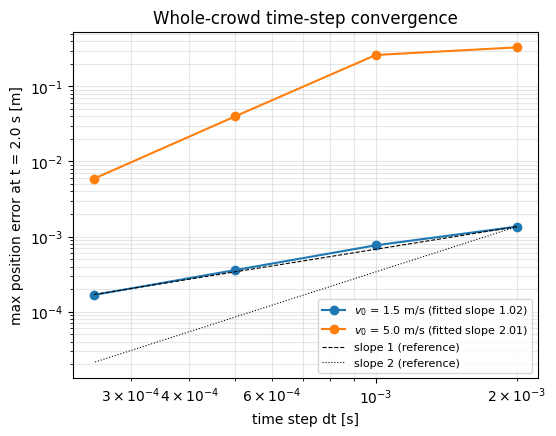

VERIFICATION: Trajectory error shrinks as dt shrinks (order reported, not assumed) -> PASS


In [104]:
# 4.9  Time-step study A: error of the whole-crowd trajectory against a very fine reference
# Compared over a SHORT horizon only: the dynamics are chaotic (cell 4.7), so any trajectory difference grows
# exponentially and a full evacuation cannot be compared run by run.
T_STUDY = 2.0                                  # [s]
DTS_A = np.array([0.002, 0.001, 0.0005, 0.00025])
DT_REF = 0.0000625
fig, ax = plt.subplots(figsize=(6, 4.5))
orders_A = {}
for v0_t in (1.5, 5.0):
    pos_t, rad_t = place_agents(PARAMS, np.random.default_rng(BASE_SEED))
    ref = run_evacuation(v0_t, BASE_SEED, dt=DT_REF, T_max=T_STUDY, use_cells=False, pos0=pos_t, rad=rad_t)['pos_end']
    errs = np.array([np.abs(run_evacuation(v0_t, BASE_SEED, dt=d, T_max=T_STUDY, use_cells=False, pos0=pos_t, rad=rad_t)['pos_end'] - ref).max()
                     for d in DTS_A])
    local = np.log(errs[:-1] / errs[1:]) / np.log(DTS_A[:-1] / DTS_A[1:])
    slope = np.polyfit(np.log(DTS_A), np.log(errs), 1)[0]
    orders_A[v0_t] = (errs, local, slope)
    print(f"v0 = {v0_t}: max position error [m] = " + ", ".join(f"{e:.1e}" for e in errs))
    print(f"        local orders = {np.round(local, 2)}, fitted slope = {slope:.2f}")
    ax.loglog(DTS_A, errs, 'o-', label=f'$v_0$ = {v0_t} m/s (fitted slope {slope:.2f})')
ax.loglog(DTS_A, orders_A[1.5][0][0] * (DTS_A / DTS_A[0]), 'k--', lw=0.8, label='slope 1 (reference)')
ax.loglog(DTS_A, orders_A[1.5][0][0] * (DTS_A / DTS_A[0]) ** 2, 'k:', lw=0.8, label='slope 2 (reference)')
ax.set_xlabel('time step dt [s]'); ax.set_ylabel(f'max position error at t = {T_STUDY} s [m]')
ax.set_title('Whole-crowd time-step convergence'); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.show()
for v0_t, (errs, local, slope) in orders_A.items():
    assert errs[-1] < errs[0], f"The error does not shrink with the time step at v0 = {v0_t}!"
print("VERIFICATION: Trajectory error shrinks as dt shrinks (order reported, not assumed) -> PASS")

In [105]:

# 4.10  Time-step study B: does the quantity we care about (mean evacuation time) depend on dt?

STUDY_SEEDS = range(BASE_SEED, BASE_SEED + N_SEEDS)
DTS_B = [0.002, 0.001, 0.0005]
V_B = (1.5, 5.0) if FULL_RUN else (3.0,)  # one speed keeps the live run short

if not FULL_RUN:
    print("Quick mode: testing only 3.0 m/s. Full mode tests 1.5 and 5.0 m/s.")

rows_B = []

for v0_t in V_B:
    for d in DTS_B:
        r = replicate(v0_t, STUDY_SEEDS, dt=d)
        rows_B.append(r)
        print(f"v0 = {v0_t}, dt = {d}: mean = {r['mean']:6.1f} +/- {r['ci_half']:4.1f} s, valid {r['n_valid']}/{r['n_seeds']}")

for v0_t in V_B:
    sub = [r for r in rows_B if r['v0'] == v0_t]
    ref_r = sub[-1]

    for r in sub[:-1]:
        se = np.sqrt(r['sd'] ** 2 / r['n_valid'] + ref_r['sd'] ** 2 / ref_r['n_valid'])
        print(f"   v0 = {v0_t}: dt = {r['dt']} vs {ref_r['dt']}: difference = {r['mean'] - ref_r['mean']:+.1f} s (std. error {se:.1f} s)")
        assert abs(r['mean'] - ref_r['mean']) < 3 * se, "Mean evacuation time still depends on dt!"

print("VERIFICATION: Mean evacuation time is insensitive to dt (within statistical noise) -> PASS")
if not FULL_RUN:
    print("Note: quick mode uses few seeds, so the standard errors are wide and this check is weak; the full run (FULL_RUN = True) gives the stronger evidence.")


Quick mode: testing only 3.0 m/s. Full mode tests 1.5 and 5.0 m/s.
v0 = 3.0, dt = 0.002: mean =   63.9 +/-  3.2 s, valid 4/4
v0 = 3.0, dt = 0.001: mean =   63.8 +/-  3.7 s, valid 4/4
v0 = 3.0, dt = 0.0005: mean =   67.6 +/-  5.5 s, valid 4/4
   v0 = 3.0: dt = 0.002 vs 0.0005: difference = -3.7 s (std. error 2.0 s)
   v0 = 3.0: dt = 0.001 vs 0.0005: difference = -3.8 s (std. error 2.1 s)
VERIFICATION: Mean evacuation time is insensitive to dt (within statistical noise) -> PASS


In [106]:
# 4.10b  Time-step rule: how many runs are lost to wall tunnelling at each dt? (full run only)
# This is the evidence behind dt_for_speed() in 3.8: the counts are printed here, not quoted in the text.
if FULL_RUN:
    SEEDS_TUN = list(range(BASE_SEED, BASE_SEED + 6))
    SPEEDS_TUN = (5.0, 7.0, 10.0)
    DTS_TUN = (0.002, 0.001, 0.0005)

    def count_losses(v0, dt, seeds):
        """One batch at (v0, dt). Returns (runs that ended with somebody outside the room, runs that failed for any reason:
        stuck, tunnelled or not conserved)."""
        pos_all = np.empty((len(seeds), len(pos_demo), 2)); rad_all = np.empty((len(seeds), len(pos_demo)))
        for j, s in enumerate(seeds):
            pos_all[j], rad_all[j] = place_agents(PARAMS, np.random.default_rng(s))
        evac, n_out, cons, tun = run_batch_core(pos_all, rad_all, v0, dt, 400.0, walls, NO_OBST, AISLE_XC, GEO, P_VEC,
                                                NX, NY, ROOM_W, ROOM_L)
        return int((tun > 0).sum()), int(np.isnan(evac).sum())

    t_tun = time.perf_counter()
    lost = {}
    print(f"tunnelled runs / failed runs (any reason), out of {len(SEEDS_TUN)} seeds:")
    for v0_t in SPEEDS_TUN:
        cells_txt = []
        for d in DTS_TUN:
            lost[(v0_t, d)] = count_losses(v0_t, d, SEEDS_TUN)
            cells_txt.append(f"dt = {d}: {lost[(v0_t, d)][0]} / {lost[(v0_t, d)][1]}")
        print(f"  v0 = {v0_t:4.1f} m/s:  " + ";  ".join(cells_txt))
    print(f"tunnelling study took {time.perf_counter() - t_tun:.0f} s")
    bad_rule = [(v0_t, dt_for_speed(v0_t)) for v0_t in SPEEDS_TUN if lost[(v0_t, dt_for_speed(v0_t))][1] > 0]
    if bad_rule:
        print("WARNING: dt_for_speed() loses runs at (v0, dt) =", bad_rule, "-> use a smaller step there and update 3.8.")
    else:
        print("VERIFICATION: dt_for_speed() loses no run at 5, 7 and 10 m/s -> PASS")
else:
    print("4.10b skipped in quick mode. Set FULL_RUN = True to run the tunnelling study.")


4.10b skipped in quick mode. Set FULL_RUN = True to run the tunnelling study.


**Final time-step rule (from 4.9, 4.10 and 4.10b).** Trajectory errors shrink as dt shrinks (4.9), and the mean evacuation time is the same within statistical noise at dt = 0.002, 0.001 and 0.0005 s (4.10: 3 m/s in the default run, 1.5 and 5 m/s in the full run). The step must also be small enough to keep people from tunnelling through walls at high desired speeds. The full-run cell 4.10b counts, for 5, 7 and 10 m/s and each of the three steps, the runs that end with somebody outside the room; `dt_for_speed()` uses 0.001 s up to 5 m/s and 0.0005 s above. The tunnelling counts are printed by 4.10b only, so this text cannot disagree with the output. The stiff body force ($k = 1.2\times10^5$ N/m) is what limits the step, and the trajectory order is irregular because the dynamics are chaotic, so the study checks convergence of the statistics, not run-by-run agreement.


In [107]:
#4.11  Verification of the pillar: analytic stand-off, a far-away pillar changes nothing, clear start, full evacuation
# (a) A single agent driven straight at a pillar must stop at: pillar centre distance = R + r + gap, gap = -B*ln(m*v0/(tau*A)).
R_p, r_a, v0_a, dt_a = 0.3, 0.30, 1.5, 0.001
gap_pred = -PARAMS['B'] * np.log(PARAMS['m'] * v0_a / (PARAMS['tau'] * PARAMS['A']))
x_a = np.array([2.0, 5.0]); v_a = np.zeros(2); e_a = np.array([1.0, 0.0])
pill_a = np.array([[5.0, 5.0, R_p]])
def acc_a(x, v):
    fx, fy = circle_force_fast(x[0], x[1], v[0], v[1], r_a, pill_a[0, 0], pill_a[0, 1], pill_a[0, 2],
                               PARAMS['A'], PARAMS['B'], PARAMS['k'], PARAMS['kappa'])
    return (PARAMS['m'] * (v0_a * e_a - v) / PARAMS['tau'] + np.array([fx, fy])) / PARAMS['m']
a_ = acc_a(x_a, v_a)
for _ in range(int(30.0 / dt_a)):
    x_new = x_a + v_a * dt_a + 0.5 * a_ * dt_a ** 2
    a_new = acc_a(x_new, v_a + a_ * dt_a)
    v_a = v_a + 0.5 * (a_ + a_new) * dt_a
    x_a, a_ = x_new, a_new
dist_sim = 5.0 - x_a[0]
dist_pred = R_p + r_a + gap_pred
print(f"stand-off from the pillar centre: simulated {dist_sim:.4f} m, predicted {dist_pred:.4f} m")
assert abs(dist_sim - dist_pred) < 1e-3, "Pillar stand-off distance does not match the analytic prediction!"

# (b) Limiting case: a pillar far outside the room cannot change anything, so the results must be identical
far = np.array([[EXIT_X, -10.0, 0.3]])
SEEDS_FAR = [BASE_SEED, BASE_SEED + 1] if FULL_RUN else [BASE_SEED]      # identical results are required for every seed, so one is a valid check
t_none = replicate(3.0, SEEDS_FAR, parallel=False)['times']
t_far = replicate(3.0, SEEDS_FAR, parallel=False, obst=far)['times']
print("no pillar:", np.round(t_none, 3), " far pillar:", np.round(t_far, 3))
assert np.allclose(t_none, t_far, equal_nan=True), "A pillar outside the room changed the result!"

# (c) The pillar must not overlap any starting position, and the evacuation must still be complete and conserving
pos_o, rad_o = place_agents(PARAMS, np.random.default_rng(BASE_SEED))
gap_min = np.linalg.norm(pos_o - pillar_default[0, :2], axis=1).min() - pillar_default[0, 2] - rad_o.max()
assert gap_min > 0.0, "The pillar overlaps the seating area!"
res_p = run_evacuation(1.5, BASE_SEED, use_cells=False, obst=pillar_default)
print(f"with pillar: out {res_p['n_out']}/150, evacuation time {res_p['evac_time']:.1f} s, conserved {res_p['conserved']}")
assert res_p['conserved'] and res_p['n_out'] == 150 and res_p['tunnelled'] == 0, "Evacuation with the pillar is broken!"
print("VERIFICATION: Pillar stand-off, far pillar changes nothing, clear start, complete evacuation -> PASS")


stand-off from the pillar centre: simulated 0.7696 m, predicted 0.7696 m
no pillar: [66.453]  far pillar: [66.453]
with pillar: out 150/150, evacuation time 104.8 s, conserved True
VERIFICATION: Pillar stand-off, far pillar changes nothing, clear start, complete evacuation -> PASS


## 5. Experiments and results



In [108]:
if FULL_RUN:
    # 5.1  Pilot sweep (groundwork for the main experiment): evacuation time against desired speed
    PILOT_SPEEDS = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0]
    PILOT_SEEDS = range(BASE_SEED, BASE_SEED + 6)       # 6 seeds for the pilot; the main sweep uses N_SEEDS
    t_pilot = time.perf_counter()
    pilot = sweep(PILOT_SPEEDS, PILOT_SEEDS)
    print(f"pilot sweep took {time.perf_counter() - t_pilot:.0f} s")
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    plot_sweep(pilot, 'no obstacle (pilot, 6 seeds)', ax=ax)
    ax.set_title('Pilot: evacuation time vs desired speed (95% CI)'); ax.legend()
    plt.show()
    means = np.array([r['mean'] for r in pilot])
    i_min = int(np.nanargmin(means))
    print(f"fastest evacuation at v0 = {PILOT_SPEEDS[i_min]} m/s ({means[i_min]:.1f} s); at {PILOT_SPEEDS[-1]} m/s: {means[-1]:.1f} s")


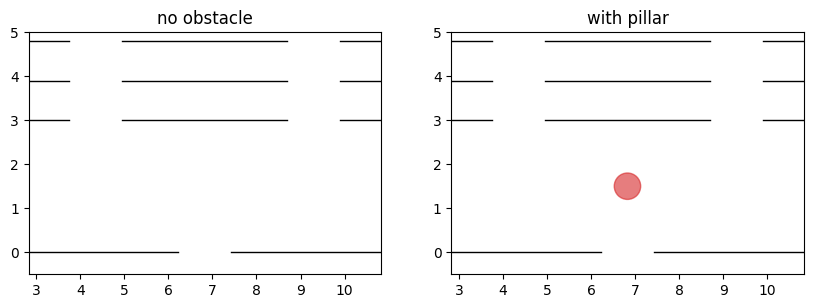

In [109]:
# 5.2  Door obstacle: one circular pillar in front of the exit (exact circle, see 3.6c, 3.9 and the check in 4.11)
pillar = make_pillar()                  # one row: centre x, centre y, radius [m]
px, py, R_p = pillar[0]

# nobody may start inside or touching the pillar
assert np.min(np.hypot(pos_demo[:, 0] - px, pos_demo[:, 1] - py)) > R_p + PARAMS['r_max']

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, ttl, show in zip(axs, ['no obstacle', 'with pillar'], [False, True]):
    for s in walls:
        ax.plot([s[0], s[2]], [s[1], s[3]], 'k-', lw=1)
    if show:
        ax.add_patch(plt.Circle((px, py), R_p, color='tab:red', alpha=0.6))
    ax.set_xlim(EXIT_X - 4, EXIT_X + 4); ax.set_ylim(-0.5, 5); ax.set_aspect('equal'); ax.set_title(ttl)
plt.show()

In [110]:
# 5.3  Replication for a modified configuration (exit width, force-law parameters); same machinery as 3.8
def replicate_cfg(v0, seeds, exit_width=None, overrides=None, obst=None, dt=None, T_max=400.0, level=0.95):
    """Like replicate() in 3.8, but with a different exit width [m] and/or different PARAMS entries
    (overrides, e.g. {'kappa': 0.0}). The same seeds give the same seat offsets and radii, so results pair with the baseline."""
    dt = dt_for_speed(v0) if dt is None else dt
    obst = NO_OBST if obst is None else obst
    pr = dict(PARAMS)
    if exit_width is not None:
        pr['exit_width'] = exit_width
    if overrides:
        pr.update(overrides)
    walls_use, _ = build_room_geometry(pr)
    P_use = np.array([pr['m'], pr['tau'], pr['A'], pr['B'], pr['k'], pr['kappa'], D_CUT, WALL_CUT])
    seeds = list(seeds)
    pos_all = np.empty((len(seeds), len(pos_demo), 2)); rad_all = np.empty((len(seeds), len(pos_demo)))
    for j, s in enumerate(seeds):
        pos_all[j], rad_all[j] = place_agents(pr, np.random.default_rng(s))
    evac, n_out, cons, tun = run_batch_core(pos_all, rad_all, v0, dt, T_max, walls_use, obst, AISLE_XC, GEO, P_use,
                                            NX, NY, ROOM_W, ROOM_L)
    valid = evac[np.isfinite(evac)]
    mean, half = mean_ci(valid, level)
    return dict(v0=v0, dt=dt, n_seeds=len(seeds), n_valid=len(valid), n_failed=len(seeds) - len(valid),
                mean=mean, ci_half=half, sd=float(valid.std(ddof=1)) if len(valid) > 1 else np.nan, times=evac)

def subset_row(rows, v0, n):
    """First n seeds of a finished sweep row at speed v0, so the baseline need not be recomputed."""
    r = next(x for x in rows if x['v0'] == v0)
    t = r['times'][:n]
    v = t[np.isfinite(t)]
    m, h = mean_ci(v)
    return dict(v0=v0, mean=m, ci_half=h, n_valid=len(v), n_seeds=n, times=t)

def paired_diff(t_a, t_b, level=0.95):
    """Mean of (a - b) over seeds where both runs succeeded, with a t-interval. Returns mean, half-width, number of pairs."""
    d = np.asarray(t_a, float) - np.asarray(t_b, float)
    d = d[np.isfinite(d)]
    m, h = mean_ci(d, level)
    return m, h, len(d)

def verdict(m, h):
    return 'clear' if (np.isfinite(h) and abs(m) > h) else 'not clear'

# checks: (a) no changes -> must reproduce replicate() exactly, (b) exit_width really sets the door gap
chk_a = replicate(3.0, [BASE_SEED, BASE_SEED + 1])['times']
chk_b = replicate_cfg(3.0, [BASE_SEED, BASE_SEED + 1])['times']
assert np.allclose(chk_a, chk_b, equal_nan=True), "replicate_cfg without changes differs from replicate!"
w2, _ = build_room_geometry({**PARAMS, 'exit_width': 2.0})
assert abs((w2[4, 0] - w2[3, 2]) - 2.0) < 1e-9, "exit width not applied to the geometry!"
print("VERIFICATION: replicate_cfg reproduces replicate; exit width sets the gap -> PASS")

VERIFICATION: replicate_cfg reproduces replicate; exit width sets the gap -> PASS


In [111]:
# 5.4  Main experiment: evacuation time vs desired speed, with and without the circular pillar
SEEDS_MAIN = range(BASE_SEED, BASE_SEED + N_SEEDS)     # same seeds for both curves (same seat offsets and body radii)

t_all = time.perf_counter()
print('--- no obstacle ---')
rows_none = sweep(SPEEDS_MAIN, SEEDS_MAIN)
print('--- circular pillar ---')
rows_obs = sweep(SPEEDS_MAIN, SEEDS_MAIN, obst=pillar)
print(f"main sweeps took {time.perf_counter() - t_all:.0f} s")


--- no obstacle ---
v0 =  1.5 m/s (dt = 0.001): mean =   98.7 +/-  2.7 s (95% CI), valid 4/4, 19.5 s
v0 =  3.0 m/s (dt = 0.001): mean =   63.8 +/-  3.7 s (95% CI), valid 4/4, 13.1 s
v0 =  7.0 m/s (dt = 0.0005): mean =   81.9 +/- 17.3 s (95% CI), valid 4/4, 37.7 s
--- circular pillar ---
v0 =  1.5 m/s (dt = 0.001): mean =  104.2 +/-  4.3 s (95% CI), valid 4/4, 21.7 s
v0 =  3.0 m/s (dt = 0.001): mean =   67.6 +/-  3.7 s (95% CI), valid 4/4, 13.9 s
v0 =  7.0 m/s (dt = 0.0005): mean =   77.1 +/-  3.5 s (95% CI), valid 4/4, 34.6 s
main sweeps took 140 s


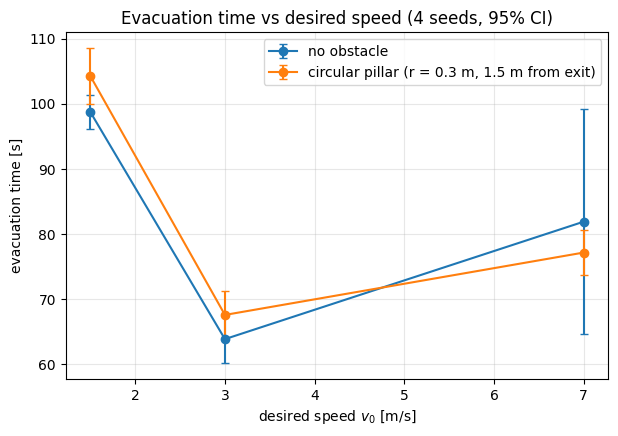

no obstacle: fastest at v0 = 3.0 m/s (63.8 s); at 7.0 m/s: 81.9 s (difference +18.0 s, std. error 5.6 s)
pillar: fastest at v0 = 3.0 m/s (67.6 s); at 7.0 m/s: 77.1 s (difference +9.6 s, std. error 1.6 s)

pillar minus no obstacle, paired by seed:
v0 =  1.5:   +5.5 +/-  4.3 s (4 paired seeds) -> pillar slower
v0 =  3.0:   +3.7 +/-  2.0 s (4 paired seeds) -> pillar slower
v0 =  7.0:   -4.7 +/- 20.1 s (4 paired seeds) -> no clear difference

runs that did not finish with everybody out (failed / total):
  no obstacle : 1.5 m/s: 0/4, 3.0 m/s: 0/4, 7.0 m/s: 0/4
  pillar      : 1.5 m/s: 0/4, 3.0 m/s: 0/4, 7.0 m/s: 0/4


In [112]:
# 5.5  Results: curves with 95% CIs, minimum, faster-is-slower check, paired obstacle comparison
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_sweep(rows_none, 'no obstacle', ax=ax)
plot_sweep(rows_obs, f"circular pillar (r = {PARAMS['obstacle_radius']} m, {PARAMS['obstacle_dist']} m from exit)", ax=ax)
ax.set_title(f'Evacuation time vs desired speed ({len(SEEDS_MAIN)} seeds, 95% CI)'); ax.legend()
plt.show()

for name, rows in (('no obstacle', rows_none), ('pillar', rows_obs)):
    means = np.array([r['mean'] for r in rows]); i = int(np.nanargmin(means))
    r_hi = rows[-1]
    se = np.sqrt(rows[i]['sd'] ** 2 / rows[i]['n_valid'] + r_hi['sd'] ** 2 / r_hi['n_valid'])
    print(f"{name}: fastest at v0 = {rows[i]['v0']} m/s ({means[i]:.1f} s); at {r_hi['v0']} m/s: {r_hi['mean']:.1f} s "
          f"(difference {r_hi['mean'] - means[i]:+.1f} s, std. error {se:.1f} s)")

print("\npillar minus no obstacle, paired by seed:")
for rn, ro in zip(rows_none, rows_obs):
    d = ro['times'] - rn['times']
    d = d[np.isfinite(d)]
    m, h = mean_ci(d)
    txt = 'pillar faster' if m + h < 0 else ('pillar slower' if m - h > 0 else 'no clear difference')   # 'txt', not 'verdict': verdict() is a function (5.3)
    print(f"v0 = {rn['v0']:4.1f}: {m:+6.1f} +/- {h:4.1f} s ({len(d)} paired seeds) -> {txt}")

table = np.array([[a['v0'], a['mean'], a['ci_half'], b['mean'], b['ci_half']] for a, b in zip(rows_none, rows_obs)])
np.savetxt(f'sweep_results_{RUN_MODE}.csv', table, delimiter=',', header='v0,mean_none,ci_none,mean_pillar,ci_pillar', comments='')
print("\nruns that did not finish with everybody out (failed / total):")
for name, rows in (('no obstacle', rows_none), ('pillar', rows_obs)):
    print(f"  {name:12s}: " + ", ".join(f"{r['v0']} m/s: {r['n_failed']}/{r['n_seeds']}" for r in rows))


width 2.0 m, v0 = 3.0 m/s: mean =   36.9 +/-  2.1 s, valid 3/3, 6 s
width 2.0 m, v0 = 7.0 m/s: mean =   26.9 +/-  3.1 s, valid 3/3, 11 s
width study took 16 s


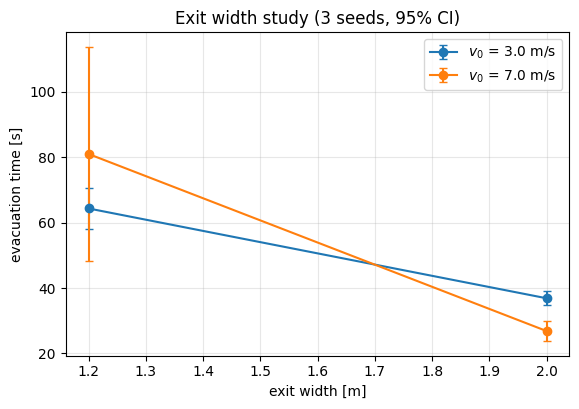


faster-is-slower penalty = time at 7.0 m/s minus time at 3.0 m/s, paired by seed:
width 1.2 m:  +16.7 +/- 28.0 s (3 pairs) -> not clear
width 2.0 m:  -10.0 +/-  1.0 s (3 pairs) -> clear


In [113]:
# 5.5b  Exit width at two speeds: how does the door width change evacuation time and the faster-is-slower penalty?
WIDTHS = [0.9, 1.2, 1.5, 2.0] if FULL_RUN else [1.2, 2.0]               # exit width [m]; 1.2 m is the baseline and comes from the main sweep
SPEEDS_W = [3.0, 7.0]                  # best speed found in 5.5, and a panic speed
SEEDS_W = list(range(BASE_SEED, BASE_SEED + N_SMALL))
n_w = len(SEEDS_W)
assert 'rows_none' in globals(), "Run 5.4 first: the 1.2 m baseline is taken from the main sweep"

res_w = {}
t_w = time.perf_counter()
for w in WIDTHS:
    for v0 in SPEEDS_W:
        if abs(w - PARAMS['exit_width']) < 1e-9:
            res_w[(w, v0)] = subset_row(rows_none, v0, n_w)       # baseline: first N_SMALL seeds of the main sweep
        else:
            t0 = time.perf_counter()
            r = res_w[(w, v0)] = replicate_cfg(v0, SEEDS_W, exit_width=w)
            print(f"width {w:.1f} m, v0 = {v0} m/s: mean = {r['mean']:6.1f} +/- {r['ci_half']:4.1f} s, "
                  f"valid {r['n_valid']}/{n_w}, {time.perf_counter() - t0:.0f} s")
print(f"width study took {time.perf_counter() - t_w:.0f} s")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for v0 in SPEEDS_W:
    ax.errorbar(WIDTHS, [res_w[(w, v0)]['mean'] for w in WIDTHS], yerr=[res_w[(w, v0)]['ci_half'] for w in WIDTHS],
                fmt='o-', capsize=3, label=f'$v_0$ = {v0} m/s')
ax.set_xlabel('exit width [m]'); ax.set_ylabel('evacuation time [s]'); ax.grid(True, alpha=0.3); ax.legend()
ax.set_title(f'Exit width study ({n_w} seeds, 95% CI)')
plt.show()

lo, hi = SPEEDS_W[0], SPEEDS_W[-1]
print(f"\nfaster-is-slower penalty = time at {hi} m/s minus time at {lo} m/s, paired by seed:")
for w in WIDTHS:
    m, h, n = paired_diff(res_w[(w, hi)]['times'], res_w[(w, lo)]['times'])
    print(f"width {w:.1f} m: {m:+6.1f} +/- {h:4.1f} s ({n} pairs) -> {verdict(m, h)}")

table_w = np.array([[w, res_w[(w, lo)]['mean'], res_w[(w, lo)]['ci_half'], res_w[(w, hi)]['mean'], res_w[(w, hi)]['ci_half']] for w in WIDTHS])
np.savetxt(f'width_results_{RUN_MODE}.csv', table_w, delimiter=',', header=f'width,mean_{lo},ci_{lo},mean_{hi},ci_{hi}', comments='')

In [114]:
# 5.6  kappa = 0: is sliding friction what makes fast crowds slow?  (the body force k stays on)
SPEEDS_W = [3.0, 7.0]
SEEDS_W = list(range(BASE_SEED, BASE_SEED + N_SMALL))
n_w = len(SEEDS_W); lo, hi = SPEEDS_W[0], SPEEDS_W[-1]
KAPPAS = [0.0]                         # sliding-friction constant [kg/(m s)]; the baseline 2.4e5 comes from the main sweep

res_k = {}
t_k = time.perf_counter()
for kap in KAPPAS:
    for v0 in SPEEDS_W:
        t0 = time.perf_counter()
        r = res_k[(kap, v0)] = replicate_cfg(v0, SEEDS_W, overrides={'kappa': kap})
        print(f"kappa = {kap:g}, v0 = {v0} m/s: mean = {r['mean']:6.1f} +/- {r['ci_half']:4.1f} s, "
              f"valid {r['n_valid']}/{n_w}, {time.perf_counter() - t0:.0f} s")
print(f"kappa study took {time.perf_counter() - t_k:.0f} s")

base_k = {v0: subset_row(rows_none, v0, n_w) for v0 in SPEEDS_W}
print(f"\nbaseline (kappa = {PARAMS['kappa']:g}): " + ", ".join(f"{v0} m/s: {base_k[v0]['mean']:.1f} s" for v0 in SPEEDS_W))
m_b, h_b, n_b = paired_diff(base_k[hi]['times'], base_k[lo]['times'])
print(f"baseline penalty ({hi} minus {lo} m/s): {m_b:+.1f} +/- {h_b:.1f} s ({n_b} pairs) -> {verdict(m_b, h_b)}")
for kap in KAPPAS:
    for v0 in SPEEDS_W:
        m, h, n = paired_diff(res_k[(kap, v0)]['times'], base_k[v0]['times'])
        print(f"kappa = {kap:g} minus baseline at {v0} m/s: {m:+6.1f} +/- {h:4.1f} s ({n} pairs) -> {verdict(m, h)}")
    m, h, n = paired_diff(res_k[(kap, hi)]['times'], res_k[(kap, lo)]['times'])
    print(f"kappa = {kap:g} penalty ({hi} minus {lo} m/s): {m:+.1f} +/- {h:.1f} s ({n} pairs) -> {verdict(m, h)}")

kappa = 0, v0 = 3.0 m/s: mean =   50.0 +/-  2.6 s, valid 3/3, 8 s
kappa = 0, v0 = 7.0 m/s: mean =   24.5 +/-  1.4 s, valid 3/3, 7 s
kappa study took 16 s

baseline (kappa = 240000): 3.0 m/s: 64.3 s, 7.0 m/s: 81.0 s
baseline penalty (7.0 minus 3.0 m/s): +16.7 +/- 28.0 s (3 pairs) -> not clear
kappa = 0 minus baseline at 3.0 m/s:  -14.4 +/-  4.3 s (3 pairs) -> clear
kappa = 0 minus baseline at 7.0 m/s:  -56.5 +/- 33.6 s (3 pairs) -> clear
kappa = 0 penalty (7.0 minus 3.0 m/s): -25.5 +/- 3.6 s (3 pairs) -> clear


exit width x0.8: change  +44.5 +/- 19.4 s (+69.1% of baseline), 3 pairs -> clear
exit width x1.2: change  -18.4 +/-  3.3 s (-28.5% of baseline), 3 pairs -> clear
A          x0.8: change  +12.2 +/- 10.1 s (+19.0% of baseline), 3 pairs -> clear
A          x1.2: change   -2.8 +/-  6.9 s ( -4.4% of baseline), 3 pairs -> not clear
sensitivity study took 50 s


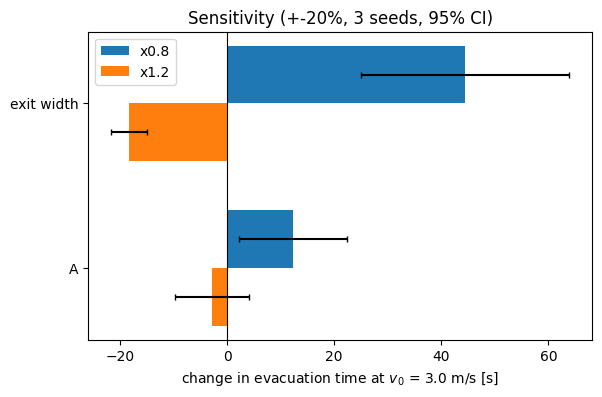

In [115]:
# 5.7  One-at-a-time sensitivity: which inputs drive the evacuation time? (+-20% on each, same seeds, paired)
V0_SENS = 3.0      # desired speed [m/s]. 3 m/s is cheap and has the tightest intervals; 7.0 would be about 3x slower
SEEDS_S = list(range(BASE_SEED, BASE_SEED + N_SMALL))
FACTORS = (0.8, 1.2)
INPUTS = {
    'exit width': lambda f: dict(exit_width=PARAMS['exit_width'] * f),
    'kappa':      lambda f: dict(overrides={'kappa': PARAMS['kappa'] * f}),
    'tau':        lambda f: dict(overrides={'tau': PARAMS['tau'] * f}),
    'A':          lambda f: dict(overrides={'A': PARAMS['A'] * f}),
    'B':          lambda f: dict(overrides={'B': PARAMS['B'] * f}),
    'k':          lambda f: dict(overrides={'k': PARAMS['k'] * f}),
}
if not FULL_RUN:
    INPUTS = {k: INPUTS[k] for k in ('exit width', 'A')}      # the two that mattered most apart from kappa, which has its own study in 5.6
base_s = subset_row(rows_none, V0_SENS, len(SEEDS_S))
sens = {}
t_s = time.perf_counter()
for name, make in INPUTS.items():
    for f in FACTORS:
        r = replicate_cfg(V0_SENS, SEEDS_S, **make(f))
        m, h, n = paired_diff(r['times'], base_s['times'])
        sens[(name, f)] = (m, h, n)
        print(f"{name:10s} x{f:.1f}: change {m:+6.1f} +/- {h:4.1f} s ({100 * m / base_s['mean']:+5.1f}% of baseline), "
              f"{n} pairs -> {verdict(m, h)}")
print(f"sensitivity study took {time.perf_counter() - t_s:.0f} s")
with open(f'sensitivity_results_{RUN_MODE}.csv', 'w') as fh:           # record of the numbers (download it in a full run)
    fh.write('input,factor,change_s,ci_half_s,pairs\n')
    for (nm_, f_), (m_, h_, n_) in sens.items():
        fh.write(f'{nm_},{f_},{m_:.3f},{h_:.3f},{n_}\n')

fig, ax = plt.subplots(figsize=(6.5, 4))
y = np.arange(len(INPUTS))
for j, f in enumerate(FACTORS):
    ms = [sens[(nm, f)][0] for nm in INPUTS]; hs = [sens[(nm, f)][1] for nm in INPUTS]
    ax.barh(y + (j - 0.5) * 0.35, ms, height=0.35, xerr=hs, capsize=2, label=f'x{f}')
ax.set_yticks(y); ax.set_yticklabels(list(INPUTS)); ax.axvline(0, color='k', lw=0.8); ax.invert_yaxis()
ax.set_xlabel(f'change in evacuation time at $v_0$ = {V0_SENS} m/s [s]'); ax.legend()
ax.set_title(f'Sensitivity (+-20%, {len(SEEDS_S)} seeds, 95% CI)')
plt.show()

In [116]:
if FULL_RUN:
    # 5.8  Jam snapshots: where are people when half have left, and how fast do they leave? (3 m/s vs 7 m/s, one seed)
    from matplotlib.patches import Circle
    from matplotlib.collections import PatchCollection

    SNAP_SEED = BASE_SEED
    runs = {}
    for v0 in (3.0, 7.0):
        dt_v = dt_for_speed(v0)
        rec = int(round(0.25 / dt_v))                      # record the people-out count every 0.25 s
        res = run_evacuation(v0, SNAP_SEED, dt=dt_v, use_cells=False, rec_every=rec)
        t_half = float(np.nanmedian(res['t_exit']))        # time at which half of the people have left
        runs[v0] = dict(res=res, dt=dt_v, rec=rec, t_half=t_half)

        te = np.sort(res['t_exit'][np.isfinite(res['t_exit'])]); n_p = len(te)
        q = 0.6 * n_p / (te[int(0.8 * n_p) - 1] - te[int(0.2 * n_p) - 1])      # flow between 20% and 80% evacuated
        print(f"v0 = {v0} m/s: evacuation time {res['evac_time']:.1f} s, half out at {t_half:.1f} s, "
              f"flow {q:.2f} persons/s = {q / PARAMS['exit_width']:.2f} persons/(m s)")
        if 'rows_none' in globals():
            t_ref = next(r for r in rows_none if r['v0'] == v0)['times'][0]
            print(f"   same seed in the main sweep: {t_ref:.1f} s (should be identical: {np.isclose(res['evac_time'], t_ref)})")

    fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1, 1, 1.1]})
    _, rad_s = place_agents(PARAMS, np.random.default_rng(SNAP_SEED))
    for ax, v0 in zip(axs[:2], (3.0, 7.0)):
        info = runs[v0]
        snap = run_evacuation(v0, SNAP_SEED, dt=info['dt'], T_max=info['t_half'], use_cells=False)
        act = snap['active']
        pos = snap['pos_end'][act]; vel = snap['vel_end'][act]; rr = rad_s[act]
        for s in walls:
            ax.plot([s[0], s[2]], [s[1], s[3]], 'k-', lw=1)
        pc = PatchCollection([Circle((x, y), r) for (x, y), r in zip(pos, rr)], cmap='viridis')
        pc.set_array(np.hypot(vel[:, 0], vel[:, 1])); pc.set_clim(0, 3.0)      # same colour scale for both panels
        ax.add_collection(pc)
        ax.set_xlim(EXIT_X - 4.5, EXIT_X + 4.5); ax.set_ylim(-0.6, 7.0); ax.set_aspect('equal')
        ax.set_title(f"$v_0$ = {v0} m/s at t = {info['t_half']:.0f} s ({int(act.sum())} still inside)")
    fig.colorbar(pc, ax=list(axs[:2]), label='speed [m/s] (scale capped at 3)', shrink=0.8)

    for v0, col in zip((3.0, 7.0), ('tab:blue', 'tab:red')):
        info = runs[v0]; h = info['res']['out_hist']
        axs[2].plot(np.arange(len(h)) * info['rec'] * info['dt'], h, color=col, label=f'$v_0$ = {v0} m/s')
    axs[2].set_xlabel('time [s]'); axs[2].set_ylabel('people out'); axs[2].grid(True, alpha=0.3); axs[2].legend()
    axs[2].set_title('People out vs time (one seed)')
    plt.show()
else:
    print("5.8 skipped in quick mode. Set FULL_RUN = True to generate the jam snapshots.")


5.8 skipped in quick mode. Set FULL_RUN = True to generate the jam snapshots.


In [117]:
if FULL_RUN:
    # 5.9  Off-centre pillar at 7 m/s: does moving the pillar sideways help? (10 seeds, paired with no pillar)
    assert 'rows_none' in globals(), "Run 5.4 first"
    V0_O = 7.0
    OFFSETS = [0.0, 0.4, 0.8]                              # sideways shift of the pillar from the exit axis [m]
    SEEDS_O = list(range(BASE_SEED, BASE_SEED + 10))       # same seeds as the main sweep
    base_o = next(r for r in rows_none if r['v0'] == V0_O)

    res_o = {}
    for off in OFFSETS:
        if off == 0.0 and 'rows_obs' in globals():
            res_o[off] = next(r for r in rows_obs if r['v0'] == V0_O)      # centred pillar: already computed in 5.4
        else:
            t0 = time.perf_counter()
            res_o[off] = replicate(V0_O, SEEDS_O, obst=make_pillar(x_offset=off))
            print(f"offset {off:.1f} m took {time.perf_counter() - t0:.0f} s")

    print(f"\nno pillar at {V0_O} m/s: {base_o['mean']:.1f} +/- {base_o['ci_half']:.1f} s")
    for off in OFFSETS:
        r = res_o[off]
        m, h, n = paired_diff(r['times'], base_o['times'])
        print(f"offset {off:.1f} m: mean = {r['mean']:6.1f} +/- {r['ci_half']:4.1f} s (valid {r['n_valid']}/{len(SEEDS_O)}); "
              f"pillar minus no pillar: {m:+6.1f} +/- {h:4.1f} s ({n} pairs) -> {verdict(m, h)}")

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.errorbar(OFFSETS, [res_o[o]['mean'] for o in OFFSETS], yerr=[res_o[o]['ci_half'] for o in OFFSETS], fmt='o-', capsize=3, label='pillar')
    ax.axhspan(base_o['mean'] - base_o['ci_half'], base_o['mean'] + base_o['ci_half'], color='gray', alpha=0.25, label='no pillar (95% CI)')
    ax.set_xlabel('pillar offset from the exit axis [m]'); ax.set_ylabel('evacuation time [s]'); ax.grid(True, alpha=0.3); ax.legend()
    ax.set_title(f'Pillar position at {V0_O} m/s (10 seeds)')
    plt.show()

In [118]:
if FULL_RUN:
    # 5.10  More seeds where the pillar comparison was inconclusive (5 and 7 m/s): 10 old + 10 new seeds, paired
    assert 'rows_none' in globals() and 'rows_obs' in globals(), "Run 5.4 first"
    V_MORE = [5.0, 7.0]
    SEEDS_NEW = list(range(BASE_SEED + 10, BASE_SEED + 20))      # the main sweep used BASE_SEED .. BASE_SEED + 9
    pillar_c = make_pillar()
    more = {}
    t_m = time.perf_counter()
    for v0 in V_MORE:
        t_old_n = next(r for r in rows_none if r['v0'] == v0)['times']
        t_old_o = next(r for r in rows_obs if r['v0'] == v0)['times']
        r_n = replicate(v0, SEEDS_NEW)                          # no pillar, new seeds
        r_o = replicate(v0, SEEDS_NEW, obst=pillar_c)           # pillar, new seeds
        t_n = np.concatenate([t_old_n, r_n['times']]); t_o = np.concatenate([t_old_o, r_o['times']])
        more[v0] = (t_n, t_o)
        mn, hn = mean_ci(t_n[np.isfinite(t_n)]); mo, ho = mean_ci(t_o[np.isfinite(t_o)])
        m, h, n = paired_diff(t_o, t_n)
        print(f"v0 = {v0} m/s ({n} pairs): no pillar {mn:.1f} +/- {hn:.1f} s, pillar {mo:.1f} +/- {ho:.1f} s; "
              f"pillar minus no pillar: {m:+.1f} +/- {h:.1f} s -> {verdict(m, h)}")
    print(f"took {time.perf_counter() - t_m:.0f} s")

In [119]:
if FULL_RUN:
    # 5.11  Pillar at the narrow door (0.9 m) at 7 m/s: does it help where the jam is strongest?
    assert 'res_w' in globals(), "Run the exit-width study (5.5b) first"
    W_N, V0_N = 0.9, 7.0
    SEEDS_N = list(range(BASE_SEED, BASE_SEED + 6))              # same seeds as the width study
    t0 = time.perf_counter()
    r_p = replicate_cfg(V0_N, SEEDS_N, exit_width=W_N, obst=make_pillar())
    base_n = res_w[(W_N, V0_N)]
    m, h, n = paired_diff(r_p['times'], base_n['times'])
    print(f"width {W_N} m, {V0_N} m/s: no pillar {base_n['mean']:.1f} +/- {base_n['ci_half']:.1f} s, "
          f"pillar {r_p['mean']:.1f} +/- {r_p['ci_half']:.1f} s (valid {r_p['n_valid']}/{len(SEEDS_N)})")
    print(f"pillar minus no pillar: {m:+.1f} +/- {h:.1f} s ({n} pairs) -> {verdict(m, h)}   [{time.perf_counter() - t0:.0f} s]")

single agent: measured convergence order (log-log slope) = 2.04
14 replications at 3 m/s: standard error falls from 1.6 s (n = 3) to 0.9 s (n = 14)
measured slope = -0.39 (theory -0.50); lag-1 autocorrelation of the seeds = +0.24 (|r| < 0.53 expected)


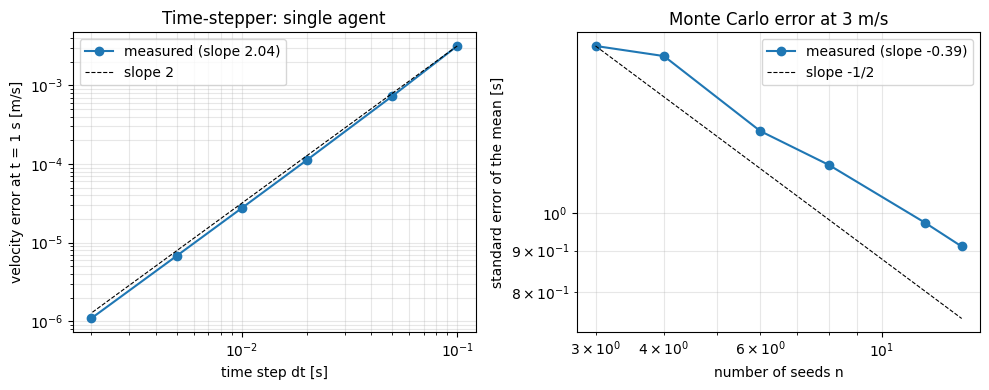

VERIFICATION (X2): error scaling measured on log-log plots: time-stepper order and 1/sqrt(n) -> PASS


In [120]:
#5.12  X2: measured error scaling (time-stepper order, and how the Monte Carlo error falls with the number of seeds)
# (a) Time-stepper: error of the single-agent velocity against the exact solution, on a log-log plot.
#     Self-contained: uses local copies of the parameters, so later changes to the globals v0, tau, t_end cannot matter.
def single_agent_velocity(dt, total_time, tau_l, v0_l):
    """Velocity Verlet, one agent, driving force only. Same scheme as cell 4.2."""
    v = 0.0
    for _ in range(int(round(total_time / dt))):
        a = (v0_l - v) / tau_l
        v_pred = v + a * dt
        a_next = (v0_l - v_pred) / tau_l
        v = v + 0.5 * (a + a_next) * dt
    return v

tau_x2, v0_x2, T_x2 = PARAMS['tau'], PARAMS['v0'], 1.0
v_exact_x2 = v0_x2 * (1.0 - np.exp(-T_x2 / tau_x2))
dts_x2 = np.array([0.1, 0.05, 0.02, 0.01, 0.005, 0.002])
err_x2 = np.array([abs(single_agent_velocity(d, T_x2, tau_x2, v0_x2) - v_exact_x2) for d in dts_x2])
slope_x2 = np.polyfit(np.log(dts_x2), np.log(err_x2), 1)[0]
print(f"single agent: measured convergence order (log-log slope) = {slope_x2:.2f}")
assert 1.8 < slope_x2 < 2.2, "Unexpected convergence order for the single-agent problem!"

# (b) Monte Carlo error: the standard error of the mean evacuation time should fall like 1/sqrt(n).
#     Uses the 3 m/s results of the main sweep (rows_none) plus extra seeds, so only the new seeds are computed.
N_MC = 32 if FULL_RUN else 14      # pool size at 3 m/s: the main-sweep seeds plus new ones (quick mode: 10 new runs, about 40 s)
# accepted range of the log-log slope (theory: -0.5). A smaller pool gives a noisier slope, so the band is wider in quick mode.
SLOPE_BAND = (-0.7, -0.3) if FULL_RUN else (-0.75, -0.2)
SEEDS_MC_NEW = list(range(BASE_SEED + N_SEEDS, BASE_SEED + N_MC))
old = next(r for r in rows_none if r['v0'] == 3.0)['times'][:N_SEEDS]
new = replicate(3.0, SEEDS_MC_NEW)['times']
pool = np.concatenate([old, new]); pool = pool[np.isfinite(pool)]
n_pool = len(pool)
rng_mc = np.random.default_rng(BASE_SEED)
ns_mc = np.array([3, 4, 6, 8, 12, 16, n_pool]); ns_mc = ns_mc[ns_mc <= n_pool]
se_mc = []
for n in ns_mc:                                          # standard error s/sqrt(n), averaged over random orderings
    se_mc.append(np.mean([pool[rng_mc.permutation(n_pool)[:n]].std(ddof=1) / np.sqrt(n) for _ in range(400)]))
se_mc = np.array(se_mc)
slope_mc = np.polyfit(np.log(ns_mc), np.log(se_mc), 1)[0]
r1 = np.corrcoef(pool[:-1], pool[1:])[0, 1]              # seeds must be independent replications
print(f"{n_pool} replications at 3 m/s: standard error falls from {se_mc[0]:.1f} s (n = {ns_mc[0]}) to {se_mc[-1]:.1f} s (n = {ns_mc[-1]})")
print(f"measured slope = {slope_mc:.2f} (theory -0.50); lag-1 autocorrelation of the seeds = {r1:+.2f} (|r| < {2 / np.sqrt(n_pool):.2f} expected)")
assert SLOPE_BAND[0] < slope_mc < SLOPE_BAND[1], f"Monte Carlo error does not fall like 1/sqrt(n)! (slope {slope_mc:.2f}, accepted {SLOPE_BAND})"
assert abs(r1) < 3 / np.sqrt(n_pool), "Neighbouring seeds look correlated!"

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].loglog(dts_x2, err_x2, 'o-', label=f'measured (slope {slope_x2:.2f})')
axs[0].loglog(dts_x2, err_x2[0] * (dts_x2 / dts_x2[0]) ** 2, 'k--', lw=0.8, label='slope 2')
axs[0].set_xlabel('time step dt [s]'); axs[0].set_ylabel('velocity error at t = 1 s [m/s]')
axs[0].set_title('Time-stepper: single agent'); axs[0].legend(); axs[0].grid(True, which='both', alpha=0.3)
axs[1].loglog(ns_mc, se_mc, 'o-', label=f'measured (slope {slope_mc:.2f})')
axs[1].loglog(ns_mc, se_mc[0] * (ns_mc / ns_mc[0]) ** -0.5, 'k--', lw=0.8, label='slope -1/2')
axs[1].set_xlabel('number of seeds n'); axs[1].set_ylabel('standard error of the mean [s]')
axs[1].set_title('Monte Carlo error at 3 m/s'); axs[1].legend(); axs[1].grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()
print("VERIFICATION (X2): error scaling measured on log-log plots: time-stepper order and 1/sqrt(n) -> PASS")

width 0.9 m: flow = 1.19 +/- 0.08 persons/s, specific flow = 1.32 persons/(m s)
width 1.2 m: flow = 1.90 +/- 0.14 persons/s, specific flow = 1.59 persons/(m s)
width 1.5 m: flow = 2.38 +/- 0.17 persons/s, specific flow = 1.59 persons/(m s)
door-limited widths (<= 1.5 m): specific flow inside the empirical range 1.2-1.8? 0.9 m: yes, 1.2 m: yes, 1.5 m: yes


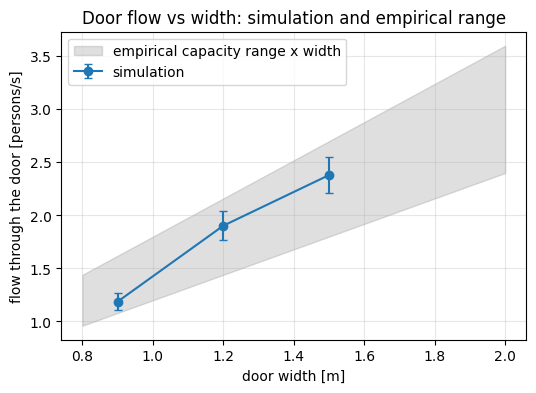

Only the door-limited widths (up to 1.5 m) are shown in the quick mode; the full run adds 1.8 m, where the aisles limit the flow.
VERIFICATION (X4): door flow grows with width and its specific value lies in the published range -> PASS


In [121]:
#5.13  X4: real-data grounding: flow through the door against published bottleneck data
# Empirical reference: Seyfried et al. [16] (arXiv:0810.1945). Sec. 2.1: the capacity J_s,max (maximum of the fundamental
# diagram, specific flow) ranges from 1.2 to 1.8 persons/(m s) across studies. Sec. 2.2: bottleneck flow in laboratory
# experiments increases continuously, almost linearly, with the width for w > 0.6 m. The same paper notes that flows
# measured at bottlenecks can exceed the fundamental-diagram maximum, so this range is a plausibility band, not a sharp target.
EMP_JS = (1.2, 1.8)                     # persons / (m s), range quoted in the paper for the capacity
X4_WIDTHS = [0.9, 1.2, 1.5, 1.8] if FULL_RUN else [0.9, 1.2, 1.5]   # door widths [m]; 1.8 m (plot only) is left out of the quick mode
X4_V0 = 1.5                             # desired speed [m/s] (nervous walking, as in the force-model paper)
N_X4 = 6 if FULL_RUN else 3
def door_flow(width, seed, v0=X4_V0):
    """Persons per second through the door, measured between the 20th and 80th percent of all exits
    (the steady stream; the start-up and the last stragglers are left out)."""
    pr = {**PARAMS, 'exit_width': width}
    w_x, _ = build_room_geometry(pr)
    pos0, rad0 = place_agents(pr, np.random.default_rng(seed))
    t_exit = run_core_fast(pos0, rad0, v0, dt_for_speed(v0), 400.0, w_x, NO_OBST, AISLE_XC, GEO, P_VEC,
                           False, NX, NY, 1000)[0]
    te = np.sort(t_exit[np.isfinite(t_exit)])
    if len(te) < 0.8 * len(pos0):
        return np.nan
    i1, i2 = int(0.2 * len(te)), int(0.8 * len(te))
    return (i2 - i1) / (te[i2] - te[i1])

flow = {}
for w_ in X4_WIDTHS:
    vals = np.array([door_flow(w_, s) for s in range(BASE_SEED, BASE_SEED + N_X4)])
    m_, h_ = mean_ci(vals[np.isfinite(vals)])
    flow[w_] = (m_, h_)
    print(f"width {w_:.1f} m: flow = {m_:.2f} +/- {h_:.2f} persons/s, specific flow = {m_ / w_:.2f} persons/(m s)")
Js = {w_: flow[w_][0] / w_ for w_ in X4_WIDTHS}
ws = np.array(X4_WIDTHS); Jm = np.array([flow[w_][0] for w_ in X4_WIDTHS])
limited = ws[ws <= 1.5]                                   # door-limited widths (wider doors: the aisles limit the supply)
print("door-limited widths (<= 1.5 m): specific flow inside the empirical range "
      f"{EMP_JS[0]}-{EMP_JS[1]}? " + ", ".join(f"{w_:.1f} m: {'yes' if EMP_JS[0] <= Js[w_] <= EMP_JS[1] else 'NO'}" for w_ in limited))
assert all(Jm[i] < Jm[i + 1] for i in range(len(limited) - 1)), "Flow does not grow with the door width!"
assert all(1.0 <= Js[w_] <= 2.0 for w_ in limited), "Specific flow is far outside the empirical range!"
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(ws, Jm, yerr=[flow[w_][1] for w_ in X4_WIDTHS], fmt='o-', capsize=3, label='simulation')
wl = np.linspace(0.8, 2.0, 20)
ax.fill_between(wl, EMP_JS[0] * wl, EMP_JS[1] * wl, color='gray', alpha=0.25, label='empirical capacity range x width')
ax.set_xlabel('door width [m]'); ax.set_ylabel('flow through the door [persons/s]'); ax.grid(True, alpha=0.3); ax.legend()
ax.set_title('Door flow vs width: simulation and empirical range'); plt.show()
if 1.8 in X4_WIDTHS:
    print("Beyond about 1.5 m the flow stops growing: the two 1.2 m aisles then limit how fast people arrive, which the "
          "laboratory bottlenecks (free supply) do not have, so only the door-limited widths are comparable.")
else:
    print("Only the door-limited widths (up to 1.5 m) are shown in the quick mode; the full run adds 1.8 m, where the aisles limit the flow.")
print("VERIFICATION (X4): door flow grows with width and its specific value lies in the published range -> PASS")


one force evaluation, 129 people inside:  NumPy baseline    5348 us   Numba fast kernels     91 us   -> 59x
estimated cost of one full 1.5 m/s evacuation (not run with NumPy): NumPy about 560 s, Numba measured about 5.6 s
3 seeds at 3 m/s (timed in 4.8): serial 11.1 s, parallel 10.2 s -> 1.1x (2 CPU cores, 2 Numba threads; identical results, asserted in 4.8)


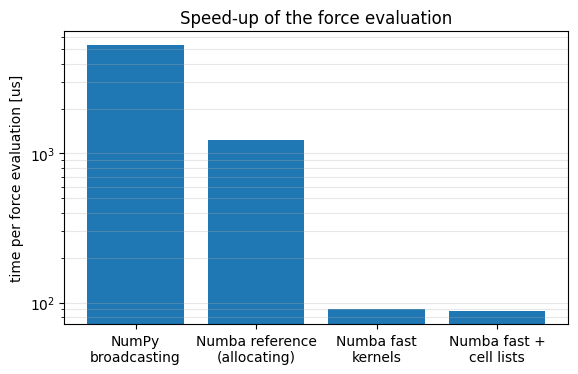

VERIFICATION (X6): measured speed-ups with identical forces -> PASS


In [122]:
# 5.14  X6: measured speed-ups (NumPy baseline -> Numba kernels -> cell lists -> parallel seeds)
import os

def numpy_forces(pos, vel, rad, A, B, k, kappa, walls_arr):
    """Pair and wall forces with plain NumPy broadcasting (the baseline a first implementation would use)."""
    diff = pos[:, None, :] - pos[None, :, :]
    d = np.linalg.norm(diff, axis=2)
    np.fill_diagonal(d, 1.0)
    n = diff / d[..., None]
    t = np.stack([-n[..., 1], n[..., 0]], axis=-1)
    ov = rad[:, None] + rad[None, :] - d
    g = np.maximum(ov, 0.0)
    fn = A * np.exp(ov / B) + k * g
    dvt = np.einsum('ijk,ijk->ij', vel[None, :, :] - vel[:, None, :], t)
    f = fn[..., None] * n + (kappa * g * dvt)[..., None] * t
    idx = np.arange(len(pos))
    f[idx, idx] = 0.0
    F = f.sum(axis=1)

    for (x1, y1, x2, y2) in walls_arr:
        a = np.array([x1, y1])
        ab = np.array([x2, y2]) - a
        s = np.clip(((pos - a) @ ab) / (ab @ ab), 0.0, 1.0)
        vec = pos - (a + s[:, None] * ab)
        dw = np.linalg.norm(vec, axis=1)
        nw = vec / dw[:, None]
        tw = np.stack([-nw[:, 1], nw[:, 0]], axis=1)
        ovw = rad - dw
        gw = np.maximum(ovw, 0.0)
        F += (A * np.exp(ovw / B) + k * gw)[:, None] * nw - (kappa * gw * np.einsum('ij,ij->i', vel, tw))[:, None] * tw

    return F


# A crowded mid-evacuation state (20 s into a 1.5 m/s run), as in cell 4.5
res_x6 = run_evacuation(1.5, BASE_SEED, T_max=20.0, use_cells=False)
pos6, vel6, act6 = res_x6['pos_end'], res_x6['vel_end'], res_x6['active']
rad6 = place_agents(PARAMS, np.random.default_rng(BASE_SEED))[1]
pi, vi, ri = pos6[act6], vel6[act6], rad6[act6]  # people still inside

A_, B_, k_, kap_ = P_VEC[2], P_VEC[3], P_VEC[4], P_VEC[5]

F_np = numpy_forces(pi, vi, ri, A_, B_, k_, kap_, walls)
F_nb = np.zeros_like(pi)
act_i = np.ones(len(pi), dtype=np.bool_)

pair_forces_brute_fast(pi, vi, ri, act_i, A_, B_, k_, kap_, D_CUT, F_nb)
wall_forces_fast(pi, vi, ri, act_i, walls, A_, B_, k_, kap_, WALL_CUT, F_nb)

assert np.abs(F_np - F_nb).max() < 1e-2, "The NumPy baseline and the Numba kernels compute different forces!"


def time_eval(fn, reps):
    fn()
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps * 1e6


t_np = time_eval(lambda: numpy_forces(pi, vi, ri, A_, B_, k_, kap_, walls), 200)


def _fast():
    pair_forces_brute_fast(pi, vi, ri, act_i, A_, B_, k_, kap_, D_CUT, F_nb)
    wall_forces_fast(pi, vi, ri, act_i, walls, A_, B_, k_, kap_, WALL_CUT, F_nb)


t_fast = time_eval(_fast, 2000)

steps_run = run_evacuation(1.5, BASE_SEED, use_cells=True)['steps']   # steps of one full 1.5 m/s evacuation

print(f"one force evaluation, {len(pi)} people inside:  NumPy baseline {t_np:7.0f} us   Numba fast kernels {t_fast:6.0f} us   -> {t_np / t_fast:.0f}x")

print(f"estimated cost of one full 1.5 m/s evacuation (not run with NumPy): NumPy about {t_np * steps_run / 1e6:.0f} s, "
      f"Numba measured about {globals().get('w_brute', float('nan')):.1f} s")

assert t_np / t_fast > 5, "Numba kernels are not clearly faster than the NumPy baseline!"


# Parallel seeds (prange): the same batch run serially and in parallel
if FULL_RUN:
    seeds6 = list(range(BASE_SEED, BASE_SEED + 4))
    t0 = time.perf_counter()
    r_ser = replicate(3.0, seeds6, parallel=False)
    t_ser = time.perf_counter() - t0

    t0 = time.perf_counter()
    r_par = replicate(3.0, seeds6, parallel=True)
    t_par = time.perf_counter() - t0

    assert np.allclose(r_ser['times'], r_par['times'], equal_nan=True), "Parallel and serial batches disagree!"

    print(f"4 seeds at 3 m/s: serial {t_ser:.1f} s, parallel {t_par:.1f} s -> {t_ser / t_par:.1f}x "
          f"({os.cpu_count()} CPU cores, {numba.get_num_threads()} Numba threads; identical results)")

elif 't_ser_chk' in globals():
    # Quick mode: reuse the timing measured in cell 4.8
    # (identical results are asserted there) instead of repeating the batch
    print(f"3 seeds at 3 m/s (timed in 4.8): serial {t_ser_chk:.1f} s, parallel {t_par_chk:.1f} s -> {t_ser_chk / t_par_chk:.1f}x "
          f"({os.cpu_count()} CPU cores, {numba.get_num_threads()} Numba threads; identical results, asserted in 4.8)")


fig, ax = plt.subplots(figsize=(6.5, 3.8))
labels = ['NumPy\nbroadcasting', 'Numba fast\nkernels']
vals = [t_np, t_fast]

if 't_ref' in globals() and 't_fc' in globals():
    labels = ['NumPy\nbroadcasting', 'Numba reference\n(allocating)', 'Numba fast\nkernels', 'Numba fast +\ncell lists']
    vals = [t_np, t_ref, t_fast, t_fc]

ax.bar(labels, vals)
ax.set_yscale('log')
ax.set_ylabel('time per force evaluation [us]')
ax.set_title('Speed-up of the force evaluation')
ax.grid(True, axis='y', which='both', alpha=0.3)
plt.show()

print("VERIFICATION (X6): measured speed-ups with identical forces -> PASS")

## 6. Discussion and limitations

*The numbers in Section 6.1 come from one full run with `FULL_RUN = True` (10 seeds, six speeds, all six sensitivity inputs, a 0.9 m door and pillar tests). The run took about 60 minutes (61.8 minutes on a 2-core Colab runtime). The default run (`FULL_RUN = False`) uses fewer seeds and tests, so its results may differ slightly. Do not compare the two runs number by number. The full-run results are the record of the numbers quoted here: they are saved in `sweep_results_full.csv`, `width_results_full.csv` and `sensitivity_results_full.csv` in the `Data/` folder. The outputs saved in this notebook are from the quick run.*

### 6.1 What the results show

**Faster is slower at higher speeds.** Without an obstacle, the average evacuation time decreased from 100.2 ± 1.5 s at 1.5 m/s to 64.3 ± 2.0 s at 3 m/s. It then increased to 66.2 ± 2.3 s at 4 m/s, 71.3 ± 5.0 s at 5 m/s and 81.9 ± 7.2 s at 7 m/s. At 7 m/s, evacuation took 17.6 s (about 27%) longer than at 3 m/s. The standard error of this difference was 3.3 s. A 6-seed pilot run gave 84.9 ± 8.6 s at 10 m/s. The results at 3 and 4 m/s are close, so the fastest evacuation occurs around this range. This supports the faster-is-slower effect described in earlier studies [1], [3].

**Why this happens.** The driving force on each person is m·v0/τ. It increases from 160 N at 1 m/s to 1120 N at 7 m/s, meaning faster crowds push harder near the exit. When sliding friction was disabled (κ = 0), evacuation time decreased from 63.1 s to 49.9 ± 1.4 s at 3 m/s and from 82.0 s to 24.6 ± 0.7 s at 7 m/s. The difference between 7 and 3 m/s changed from +18.9 ± 8.4 s to −25.3 ± 1.9 s. This suggests that sliding friction is important for producing the faster-is-slower effect in this model. The body force remained active during this test.

**Door width.** Door width had the largest effect on evacuation time. At 3 m/s, a 20% narrower door (0.96 m) increased evacuation time by 47.5 ± 6.4 s (75%). A 20% wider door (1.44 m) reduced it by 16.8 ± 3.3 s (27%). The difference between evacuation times at 7 and 3 m/s also decreased as the door became wider: +71.0 ± 23.0 s at 0.9 m, +18.9 ± 8.4 s at 1.2 m, −3.0 ± 2.3 s at 1.5 m and −9.7 ± 0.9 s at 2.0 m. This shows that wider doors reduce the faster-is-slower effect. At 1.5 m and above, the faster crowd evacuated more quickly. The 0.9 m door also had a high evacuation time at 7 m/s (204.9 ± 20.8 s), suggesting heavy congestion near the exit.

**Sensitivity to other inputs.** Each input was changed by ±20% separately at 3 m/s. The social-force strength (A) had the second-largest effect. Reducing A by 20% increased evacuation time by 12.2 ± 3.5 s (19%), while increasing it had no clear effect. One possible reason is that weaker repulsion allows more physical contact between people. The range (B) had almost no effect (±0.7%). Increasing κ or τ by 20% increased evacuation time by 6.3% and 6.0%, while reducing k by 20% increased it by 5.7%. Although these changes were flagged as clear, their effects were small. Since 12 comparisons were made using only 6 seeds, some results may be due to chance. Therefore, they are not discussed further.

**Obstacle.** The column (radius 0.3 m, placed 1.5 m in front of the exit) increased evacuation time at speeds up to 4 m/s. The increases were 3.8 s, 4.6 s, 4.2 s and 7.0 s at 1.5, 2, 3 and 4 m/s, respectively. At 5 and 7 m/s, evacuation time decreased slightly by 0.3 s and 6.2 s. Therefore, the column did not consistently improve evacuation. Off-centre placement is tested in cell 5.9 (full run only); see Section 6.4.

**Numerical robustness.** Results for dt = 0.002, 0.001 and 0.0005 s were similar. At 5 m/s, the differences compared with dt = 0.0005 s were −4.5 s and −3.0 s, with standard errors of 2.7 s and 2.9 s. However, cell 4.10b (6 seeds) shows that dt = 0.002 s loses every run to wall tunnelling at 7 and 10 m/s, dt = 0.001 s loses one run at 10 m/s, and dt = 0.0005 s loses none. Therefore, dt = 0.001 s is used up to 5 m/s and dt = 0.0005 s for higher speeds. Individual runs may differ because small numerical changes grow over time. Therefore, averages across multiple seeds are more reliable.

### 6.2 Limitations

- **2D model with round bodies.** The model ignores the sloping floor. People cannot turn sideways, step over seats or squeeze through gaps. No one falls or gets injured. At narrow doors, the model may also prevent the last person from leaving because of the repulsion from the door frame. This is a limitation of the model.

- **Assumed layout and movement rules.** The seat positions, aisle widths and movement paths are assumptions rather than real measurements. The seat-backs make each row a single-file path. An earlier movement rule caused people from opposite sides to block each other at the aisle entrance. The current rule was designed to avoid this problem.

- **Parameters are not based on real panic data.** The forces, masses and body sizes come from the original model [1]. Since there is no suitable real evacuation dataset for validation, the results are useful for comparing different scenarios but not for predicting actual evacuation times.

- **Same desired speed for everyone.** The model does not include different walking speeds, herding behaviour or increasing impatience. Real crowds may contain both calm and pushing people.

- **Limited number of simulations.** The full run uses 6 to 10 seeds per case, while the default run uses only 3 or 4. Confidence intervals are wider at higher speeds (±7 s at 7 m/s). Unfinished runs are excluded from the averages, which may make high-speed evacuation times appear lower than they really are. Their number is reported in cell 5.5.

- **Limited pillar tests.** Only one circular pillar (radius 0.3 m), placed 1.5 m from the exit at a few sideways positions, was tested. Other pillar sizes, shapes and distances were not studied.

- **Simulation speed.** The cell-list neighbour search was checked against brute force. However, with 150 people, it was not faster on Colab, so brute force was used for the experiments.

### 6.3 Future work

Future work could test different pillar sizes, shapes and positions, allow people to turn sideways at narrow doors, include different walking speeds and impatience, and compare the model with real evacuation drills. Larger crowds could also be tested to see whether cell-list searches become more efficient.

**Web demo reference value:** With the default settings (no obstacle, 1.2 m exit width and 3.0 m/s desired speed), the web demo should produce an average evacuation time of **64.3 s (95% CI ± 2.0 s)** over 10 seeds (Section 5.4). The demo result should be within **±5 s**, averaged over at least 10 runs.

**Web demo reference value (7 m/s):** With no obstacle, a 1.2 m exit and a desired speed of 7.0 m/s (dt = 0.0005 s), the web demo should produce an average evacuation time of **81.9 s (95% CI ± 7.2 s)** over 10 seeds (Section 5.4). The result should be within **±10 s**, averaged over at least 10 runs. The wider tolerance accounts for the greater variation at this speed.

### 6.4 Follow-up studies (full run only)

*These come from cells 5.9 to 5.11 and need `FULL_RUN = True`. All differences are paired by seed and given with 95% confidence intervals.*

**Off-centre pillar at 7 m/s (10 seeds, no pillar: 81.9 ± 7.2 s).** Moving the pillar sideways did not help. The centred pillar gave 75.8 ± 3.2 s (difference −6.2 ± 7.8 s), the 0.4 m offset gave 80.7 ± 6.9 s (−1.2 ± 8.8 s) and the 0.8 m offset gave 81.3 ± 5.6 s (−0.6 ± 6.7 s). Every interval contains zero, so none of the three positions is distinguishable from having no pillar. The point estimates drift towards zero as the pillar moves away from the exit axis, but with 10 seeds this trend is not established.

**More seeds (20 pairs).** Doubling the seeds narrowed the intervals but did not change the picture. At 5 m/s the pillar changed the time by −1.0 ± 3.7 s and at 7 m/s by −3.4 ± 5.2 s (no pillar 80.6 ± 4.0 s, pillar 77.1 ± 3.1 s). Both are not clear. At 7 m/s the pillar may be slightly faster, but the data do not show it.

**Pillar at the 0.9 m door (7 m/s, 6 seeds).** Here the jam is strongest, yet the pillar made no clear difference: 204.9 ± 20.8 s without and 206.9 ± 16.9 s with the pillar (−2.1 ± 19.7 s over 5 pairs). Only 5 of 6 pillar runs finished, and the unfinished run is excluded, so this result is the least certain.

**Summary.** In every geometry and speed we tested, a circular pillar of radius 0.3 m in front of the exit gave no clear benefit. At 1.5 to 3 m/s it clearly slowed the evacuation (6.1). We therefore cannot recommend a pillar as a safety measure in this model, and the earlier finding that it does not help is not an artefact of the pillar position or the number of seeds.


## 7. References

[1] D. Helbing, I. Farkas, and T. Vicsek, "Simulating dynamical features of escape panic," *Nature*, vol. 407, pp. 487–490, 2000, doi: 10.1038/35035023.

[2] D. Helbing and P. Molnár, "Social force model for pedestrian dynamics," *Phys. Rev. E*, vol. 51, no. 5, pp. 4282–4286, 1995, doi: 10.1103/PhysRevE.51.4282.

[3] J. M. Pastor *et al.*, "Experimental proof of faster-is-slower in systems of frictional particles flowing through constrictions," *Phys. Rev. E*, vol. 92, no. 6, Art. no. 062817, 2015, doi: 10.1103/PhysRevE.92.062817.

[4] I. M. Sticco, G. A. Frank, and C. O. Dorso, "Effects of the body force on the pedestrian and the evacuation dynamics," *Saf. Sci.*, vol. 129, Art. no. 104829, Sep. 2020, doi: 10.1016/j.ssci.2020.104829.

[5] D. R. Parisi and C. O. Dorso, "Microscopic dynamics of pedestrian evacuation," *Physica A*, vol. 354, pp. 606–618, 2005, doi: 10.1016/j.physa.2005.02.040.

[6] G. A. Frank and C. O. Dorso, "Room evacuation in the presence of an obstacle," *Physica A*, vol. 390, no. 11, pp. 2135–2145, 2011, doi: 10.1016/j.physa.2011.01.015.

[7] A. Schadschneider, W. Klingsch, H. Klüpfel, T. Kretz, C. Rogsch, and A. Seyfried, "Evacuation dynamics: Empirical results, modeling and applications," in *Encyclopedia of Complexity and Systems Science*, R. A. Meyers, Ed. New York, NY, USA: Springer, 2009, pp. 3142–3176, arXiv:0802.1620.

[8] W. C. Swope, H. C. Andersen, P. H. Berens, and K. R. Wilson, "A computer simulation method for the calculation of equilibrium constants for the formation of physical clusters of molecules: Application to small water clusters," *J. Chem. Phys.*, vol. 76, no. 1, pp. 637–649, 1982, doi: 10.1063/1.442716.

[9] L. Verlet, "Computer 'experiments' on classical fluids. I. Thermodynamical properties of Lennard-Jones molecules," *Phys. Rev.*, vol. 159, no. 1, pp. 98–103, 1967, doi: 10.1103/PhysRev.159.98.

[10] M. P. Allen and D. J. Tildesley, *Computer Simulation of Liquids*, 2nd ed. Oxford, U.K.: Oxford Univ. Press, 2017.

[11] A. M. Law, *Simulation Modeling and Analysis*, 5th ed. New York, NY, USA: McGraw-Hill, 2015.

[12] C. R. Harris *et al.*, "Array programming with NumPy," *Nature*, vol. 585, no. 7825, pp. 357–362, 2020, doi: 10.1038/s41586-020-2649-2.

[13] P. Virtanen *et al.*, "SciPy 1.0: Fundamental algorithms for scientific computing in Python," *Nat. Methods*, vol. 17, pp. 261–272, 2020, doi: 10.1038/s41592-019-0686-2.

[14] J. D. Hunter, "Matplotlib: A 2D graphics environment," *Comput. Sci. Eng.*, vol. 9, no. 3, pp. 90–95, 2007, doi: 10.1109/MCSE.2007.55.

[15] S. K. Lam, A. Pitrou, and S. Seibert, "Numba: A LLVM-based Python JIT compiler," in *Proc. 2nd Workshop on the LLVM Compiler Infrastructure in HPC (LLVM '15)*, Austin, TX, USA, Nov. 2015, Art. no. 7, doi: 10.1145/2833157.2833162.

[16] A. Seyfried, M. Boltes, J. Kähler, W. Klingsch, A. Portz, T. Rupprecht, A. Schadschneider, B. Steffen, and A. Winkens, "Enhanced empirical data for the fundamental diagram and the flow through bottlenecks," in *Pedestrian and Evacuation Dynamics 2008*. Berlin, Germany: Springer, 2010, doi: 10.1007/978-3-642-04504-2_11, arXiv:0810.1945.

In [123]:
elapsed_min = (time.time() - T_START) / 60
print(f"Total run time: {elapsed_min:.1f} min")
if FULL_RUN:
    print("Full run finished. Download sweep_results_full.csv, width_results_full.csv and sensitivity_results_full.csv from the Colab file pane "
          "(left sidebar) into Data/ as the record of the numbers in Section 6.")
elif elapsed_min > 10.0:
    print("Note: this runtime was slower than the quick-mode target of about 9 minutes; see the quick-mode settings in the setup cell.")


Total run time: 8.9 min
